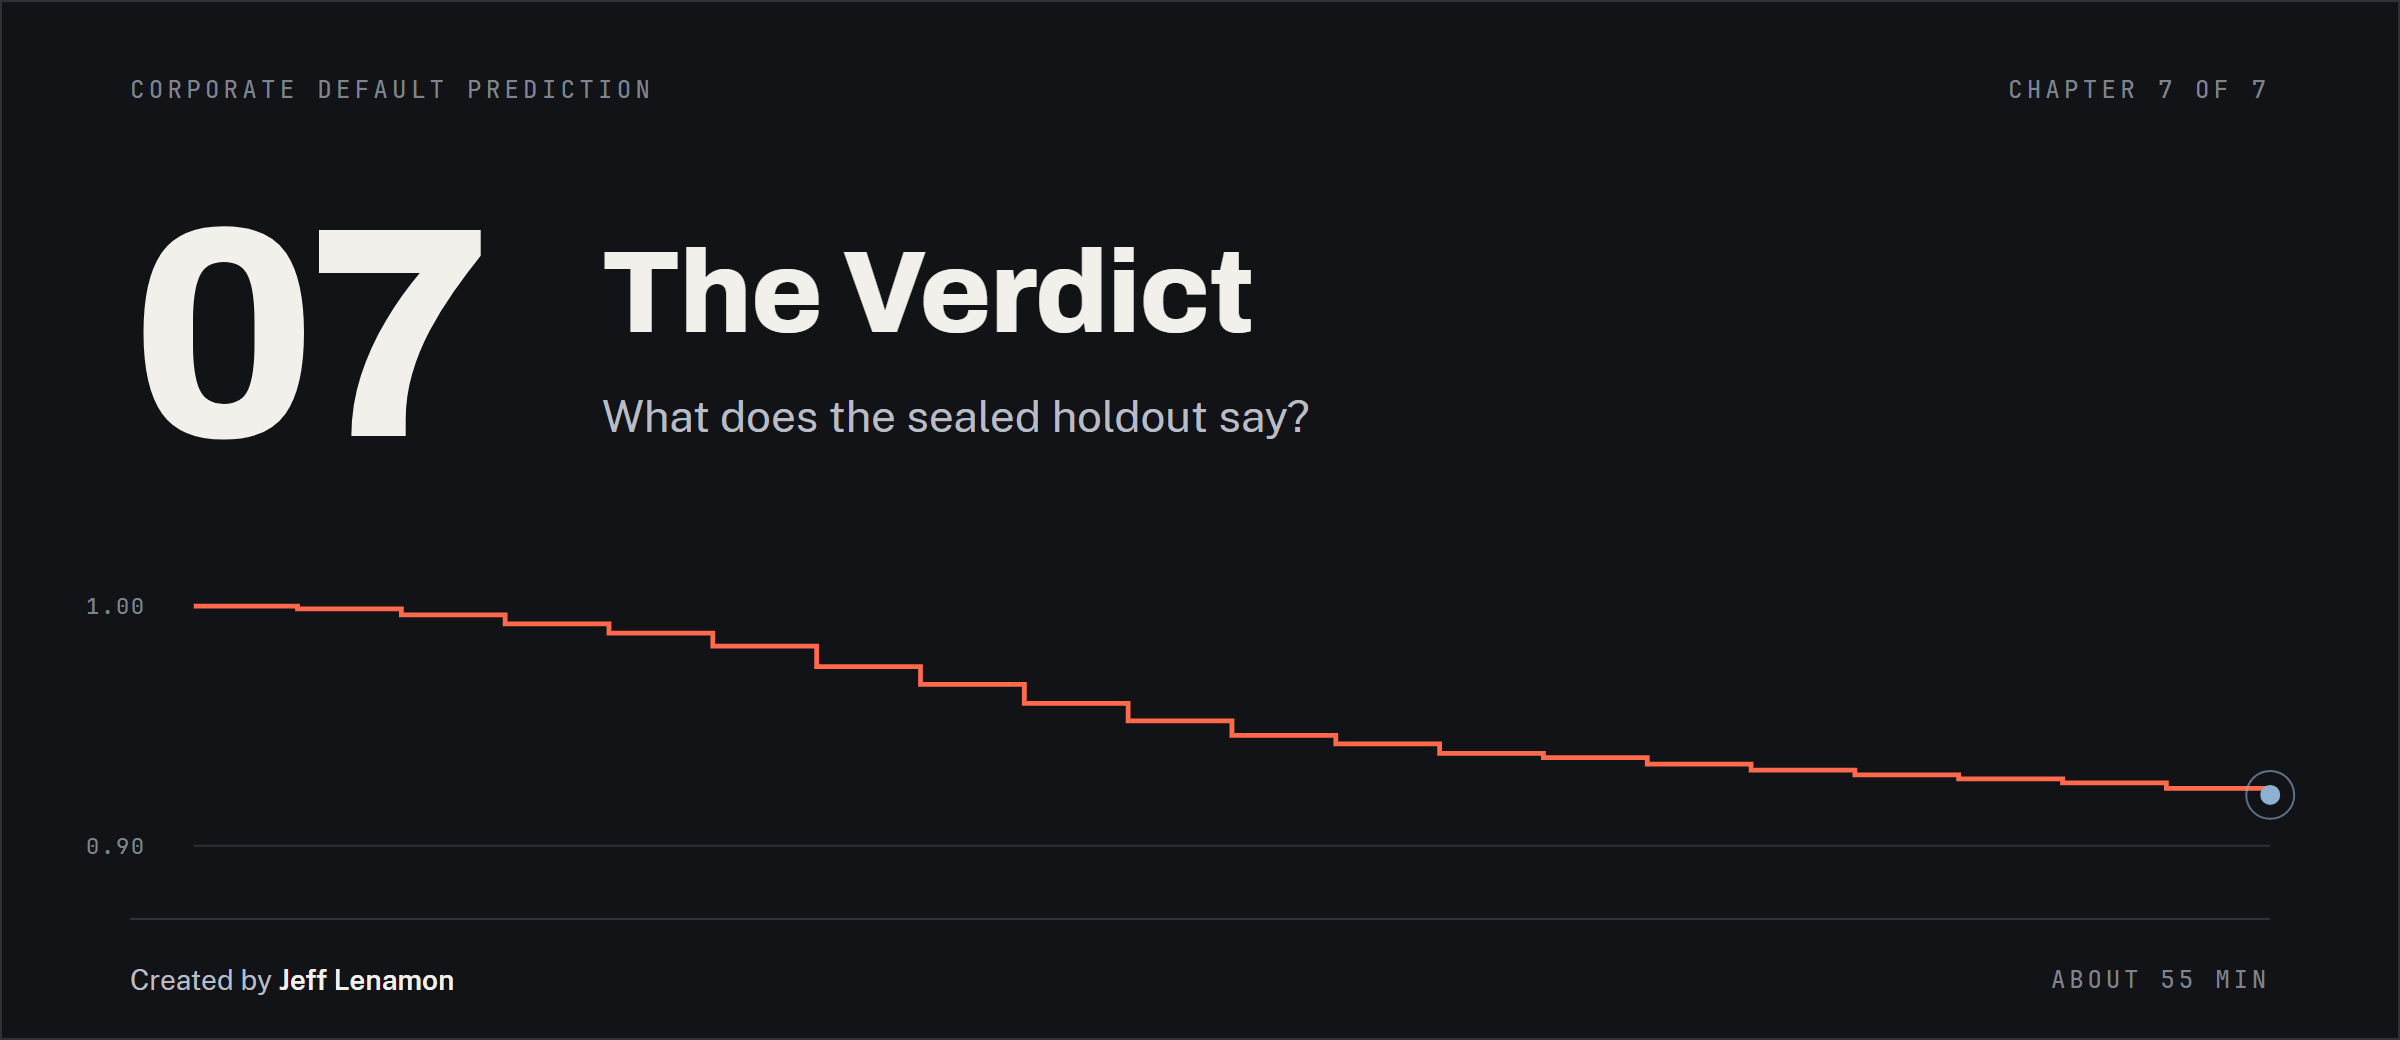

# Chapter 7: The Verdict

The models are frozen, the choice is made, and the years no model has seen are opened once.

> This casebook is educational content created in a personal capacity

> Nothing here is investment advice or a recommendation to buy or sell any security

> The data is a public research dataset with anonymised company names

## The Question

Six chapters built a label, a set of ratios, a yardstick, and seven models.
Every choice among them was made on the same development years, and a choice made on data flatters itself.

Three later years have been kept sealed the whole time.
What does the sealed holdout say?

## What You Will Learn

By the end you can:

- fix a model, a choice, and a comparison before a test set is opened;
- turn a ranking into a probability of default, and say what the probability leaves out;
- read a holdout result with its interval, and tell a coarse ordering from a fine one;
- explain a score by ratio family, and for one company;
- write the limits of a study in plain words.

## What You Need

Chapter 3, which wrote the `features` table, and Chapters 4 to 6, which wrote the out-of-fold scores of the seven rungs and the record of how each is built.

This is the only chapter that reads the outcomes of the holdout years.
It does so in one cell.

It writes the results that the front page of this casebook quotes.

## Your Route

![Your route through Chapter 7: 1 Setting Up, 5 minutes; 2 From Scores to Probabilities, 7 minutes; 3 A Master Scale, 3 minutes; 4 Opening the Holdout, 3 minutes; 5 The Ladder, 4 minutes; 6 Capture Curves, 2 minutes; 7 Did the Probabilities Hold, 3 minutes; 8 Robustness, 3 minutes; 9 What Drives the Score, 7 minutes; 10 Three Case Files, 3 minutes; 11 How Early Does It See, 2 minutes; 12 Limits, 3 minutes.](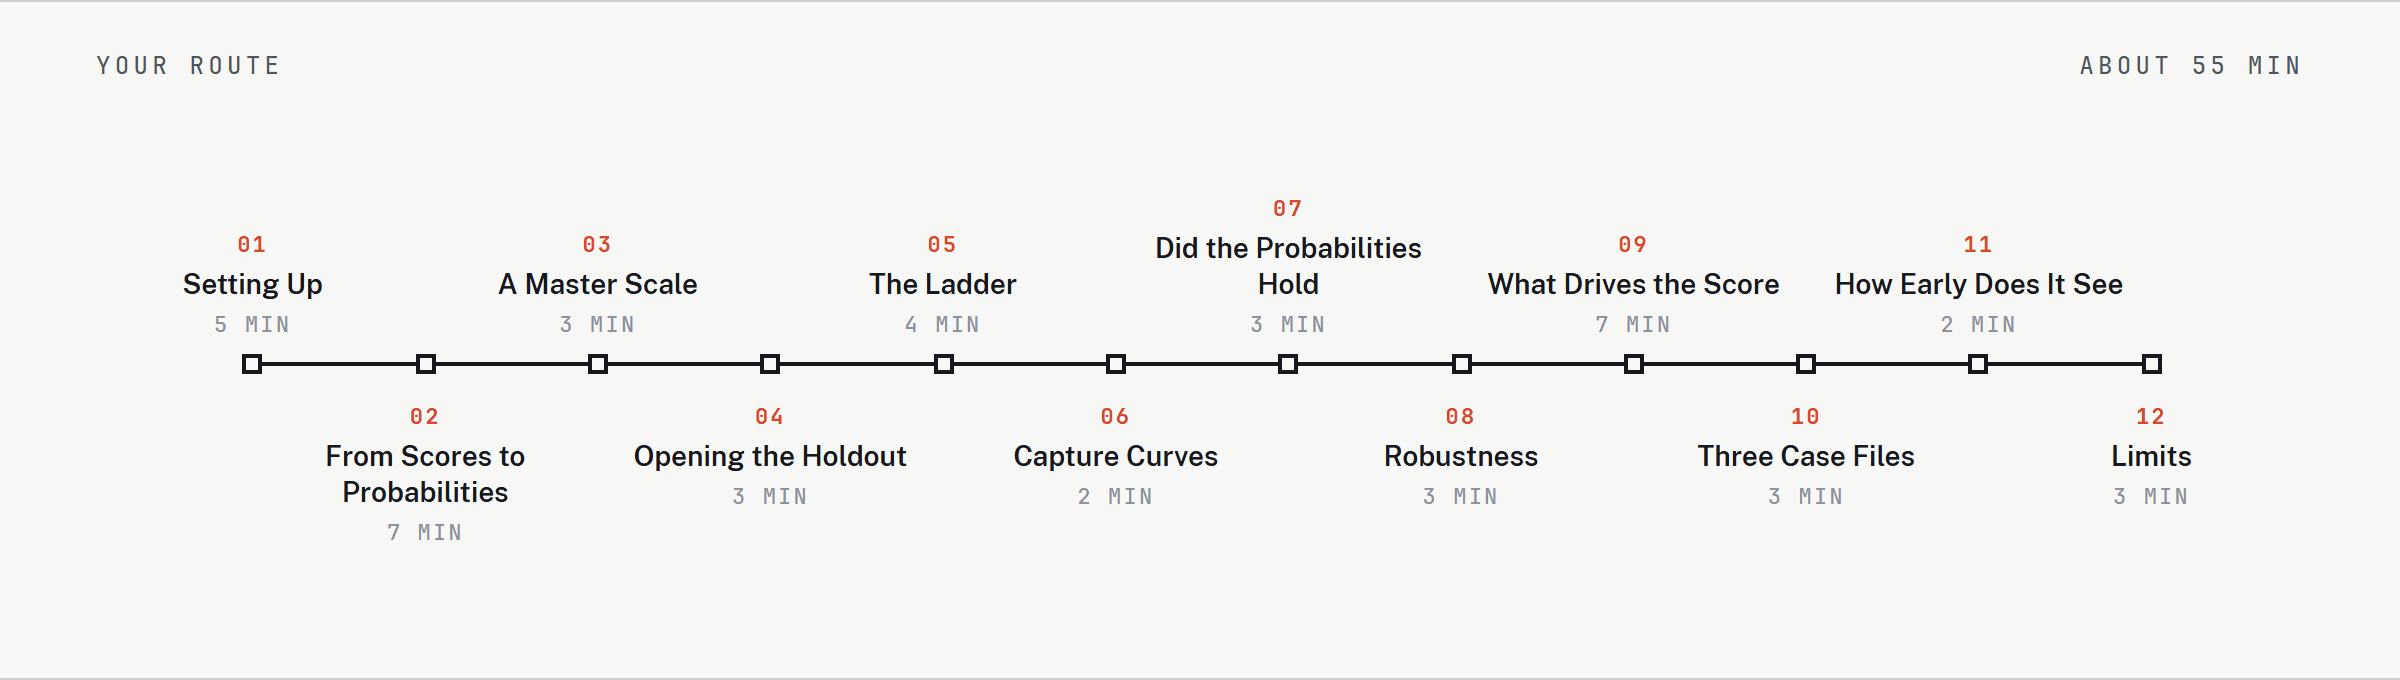)

**Time.** About 48 minutes to read and run, then about 9 for Your Turn.

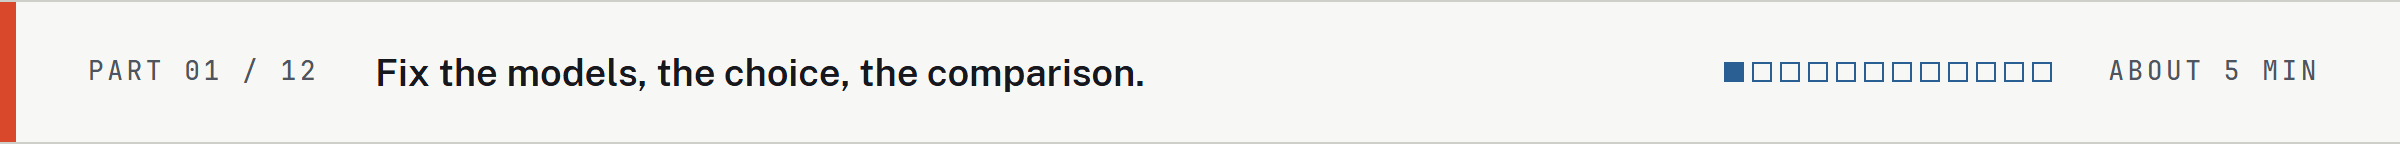

# Setting Up

Make sure the Jupyter kernel `corp-default` is selected before you run a cell.
If it is not in the list, or an import fails, the [Quick Start](../README.md#quick-start) shows how to register it and refresh the list.

## The Data Dictionary

The chapter reads `features`, the out-of-fold scores, and the record of the seven models.
It builds two columns of its own.

| Name | What it holds |
| --- | --- |
| **PD** | A probability of default: the chance that a firm-year is followed by a final filing within two years |
| **Grade** | One of seven bands of a score's percentile within its year, from the safest, one, to the riskiest, seven |

Five words are new.

| Term | What it means |
| --- | --- |
| **Calibration** | Turning a score into a probability that matches how often the event happens |
| **Brier score** | The mean squared gap between a probability and the outcome, lower being better |
| **Master scale** | A fixed set of grades, each with its own probability of default |
| **Holdout** | The observation years 2014 to 2016, sealed since Chapter 4 |
| **SHAP value** | The part of one row's score that is credited to one of its inputs |

Q. What does the chapter need before it starts?

In [1]:
from collections.abc import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import torch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator, PercentFormatter
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from xgboost import XGBClassifier

from corp_default import store, viz
from corp_default.classic import altman_z
from corp_default.evaluate import KEYS, SEED, paired_table, scoreboard
from corp_default.features import FAMILIES, fit_prepare
from corp_default.labels import PANEL_END
from corp_default.metrics import (
    capture_curve,
    cluster_bootstrap_ci,
    company_resamples,
    wilson_interval,
    within_year_percentile,
)
from corp_default.nets import TabularNet, predict, seed_everything, train_net
from corp_default.splits import DEV_END, FOLD_YEARS, HOLDOUT, development, holdout

store.open_chapter(7)
viz.use_house_style()
SOURCE = "Lombardo et al. (2022), Kaggle copy"
OOF_SOURCE = f"{SOURCE}; out-of-fold rows, {FOLD_YEARS[0]} to {FOLD_YEARS[-1]}"
COLORS = viz.MODEL_COLORS

features = store.load_frame("features")
oof_scores = store.load_frame("oof_scores")
frozen = store.load_json("frozen")

**Reading.** The table of Chapter 3, the scores of Chapters 4 to 6, and the record of each model are in memory.
`store.put` carries a number from a cell into the text, so no number in this chapter is typed by hand.

Q. What do the scores so far look like?

In [2]:
oof_scores.head()

,company_name,year,target,score,pct,model
0,C_1,2005,0,-2.878107,0.550540,Altman Z
1,C_2,2005,0,-2.412993,0.610324,Altman Z
2,C_3,2005,0,-6.339636,0.217767,Altman Z
3,C_4,2005,0,-1.971397,0.674670,Altman Z
4,C_6,2005,0,-0.554995,0.818968,Altman Z


**Reading.** Each row is one firm-year scored by one model: the score, and its percentile within the year.

Q. How large are the tables, and how do the seven rungs rank the same rows?

In [3]:
ladder = {
    name: part.drop(columns="model").reset_index(drop=True)
    for name, part in oof_scores.groupby("model", sort=False)
}
dev = development(features).reset_index(drop=True)
RATIOS = [name for members in FAMILIES.values() for name in members]

store.put("holdout_first", HOLDOUT[0])
store.put("holdout_last", HOLDOUT[1])
store.put("dev_first", int(dev["year"].min()))
store.put("dev_last", DEV_END)
store.put("n_rungs", len(ladder))
store.put("n_oof", len(next(iter(ladder.values()))))

print(features.shape, dev.shape)
oof_scores.info()
pd.DataFrame({name: oof["pct"] for name, oof in ladder.items()}).describe().T.round(3)

(72393, 73) (55524, 73)
<class 'pandas.DataFrame'>
RangeIndex: 187523 entries, 0 to 187522
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   company_name  187523 non-null  str    
 1   year          187523 non-null  int64  
 2   target        187523 non-null  int64  
 3   score         187523 non-null  float64
 4   pct           187523 non-null  float64
 5   model         187523 non-null  str    
dtypes: float64(2), int64(2), str(2)
memory usage: 8.6 MB


,count,mean,std,min,25%,50%,75%,max
Altman Z,26789.0,0.5,0.289,0.0,0.25,0.5,0.75,1.0
"Five ratios, refitted",26789.0,0.5,0.289,0.0,0.25,0.5,0.75,1.0
"All ratios, logistic",26789.0,0.5,0.289,0.0,0.25,0.5,0.75,1.0
"All ratios, trees",26789.0,0.5,0.289,0.0,0.25,0.5,0.75,1.0
Plus history,26789.0,0.5,0.289,0.0,0.25,0.5,0.75,1.0
"Network, all ratios",26789.0,0.5,0.289,0.0,0.25,0.5,0.75,1.0
"Blend, trees and network",26789.0,0.5,0.289,0.0,0.25,0.5,0.75,1.0


**Reading.** The 7 rungs each score the same 26,789 out-of-fold rows.
Every percentile runs evenly from zero to one, by construction, so the rungs differ only in which firm-years they put at the top.

Q. What does the record say about each model, and which one was chosen?

In [4]:
record = pd.DataFrame(
    [
        {
            "rung": k + 1,
            "model": name,
            "kind": spec["kind"],
            "inputs": len(spec.get("features", spec.get("members", []))),
            "chosen": spec["chosen"],
        }
        for k, (name, spec) in enumerate(frozen.items())
    ]
).set_index("rung")
CHOSEN = record.loc[record["chosen"], "model"].item()
CLASSIC = record["model"].iloc[0]
walked = paired_table({CLASSIC: ladder[CLASSIC], CHOSEN: ladder[CHOSEN]}, [CLASSIC, CHOSEN]).iloc[0]
walked_board = scoreboard({CHOSEN: ladder[CHOSEN]}).iloc[0]

store.put("chosen", CHOSEN)
store.put("classic", CLASSIC)
store.put("walked_auc", walked_board["roc_auc"])
store.put("walked_capture_5", walked_board["capture_5"])
store.put("walked_step", walked["roc_auc_diff"])
store.put("walked_step_low", walked["roc_auc_diff_lo"])
store.put("walked_step_high", walked["roc_auc_diff_hi"])

record

,model,kind,inputs,chosen
rung,,,,
1,Altman Z,published score,5,False
2,"Five ratios, refitted",logistic regression,5,False
3,"All ratios, logistic",logistic regression,24,False
4,"All ratios, trees",gradient boosting,24,True
5,Plus history,gradient boosting,45,False
6,"Network, all ratios",tabular network,24,False
7,"Blend, trees and network",mean of within-year percentiles,2,False


**Reading.** The record holds every setting that Chapters 4 to 6 chose, and it marks one model as chosen: "All ratios, trees".

Three things are fixed here, before any outcome of the holdout years is read.

- **The models.** Each of the seven rungs is refitted on the development years, 1999 to 2011, with the settings in the record and nothing tuned again.
- **The choice.** The model named in Chapter 6 by two tests, both fixed before the holdout was opened: the highest mean average precision over the seven folds, and the simpler model unless a blend beats it with an interval above zero.
- **The primary comparison.** The chosen model against "Altman Z", as a paired difference in ROC-AUC on the holdout, with the share of failures the chosen model finds at the middle budget beside it.

On the walk-forward that difference is 0.071, with an interval from 0.046 to 0.096.
The chosen model scores 0.776 there and finds 21.7% of failures at the middle budget.

Everything else the chapter reports about the holdout is description, and is to be read as such.

**Next, a probability for every score, still on the development years.**

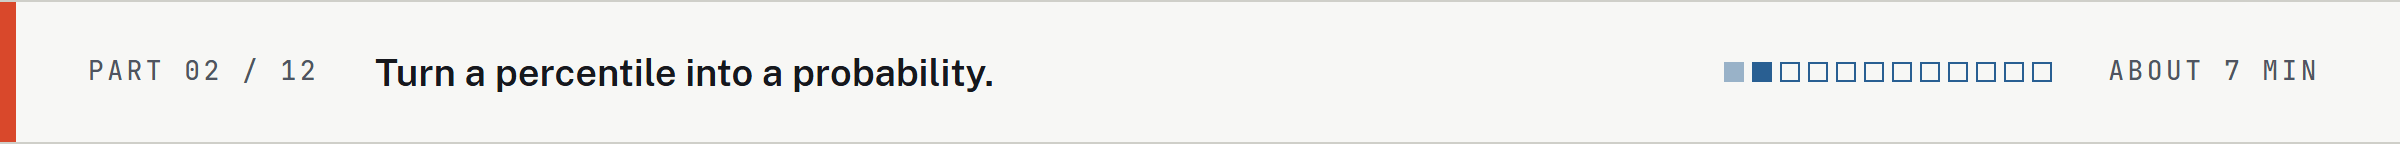

# From Scores to Probabilities

A ranking tells a desk which names to read first.
A credit decision also needs a level: a **probability of default**, or PD.

The model's own output is a poor PD.
Chapter 5 found it too low on average, because each fold's model learned the failure rate of its training years.

So the PD is built from the scale the ladder already uses, the percentile within the year.
That scale means the same thing for every fold's model and for the final one.

Two standard maps from a score to a probability are tried.
**Platt scaling** fits a smooth curve, a logistic regression on the score, and **isotonic regression** fits a staircase that may only step up.

Each is **cross-fitted** by year: the map for one year is fitted on the other six.
The rule is written first: the map with the lower Brier score on those cross-fitted probabilities is the one that goes forward.

Q. Which map does the rule choose?

In [5]:
def logit(p: np.ndarray) -> np.ndarray:
    """Log odds, with the ends held just inside zero and one."""
    p = np.clip(np.asarray(p, dtype=float), 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))


def platt(rows: pd.DataFrame) -> Callable:
    """A logistic curve from percentile to probability, fitted on `rows`."""
    curve = LogisticRegression(C=np.inf, max_iter=1000).fit(
        logit(rows["pct"])[:, None], rows["target"]
    )
    return lambda pct: curve.predict_proba(logit(pct)[:, None])[:, 1]


def isotonic(rows: pd.DataFrame) -> Callable:
    """A rising staircase from percentile to probability, fitted on `rows`."""
    return IsotonicRegression(out_of_bounds="clip").fit(rows["pct"], rows["target"]).predict


def cross_fit(make_map: Callable, rows: pd.DataFrame) -> np.ndarray:
    """A probability for every row, from a map fitted on the other years."""
    out = np.zeros(len(rows))
    for year in sorted(rows["year"].unique()):
        held = (rows["year"] == year).to_numpy()
        out[held] = make_map(rows.loc[~held])(rows.loc[held, "pct"])
    return out


chosen_oof = ladder[CHOSEN]
MAPS = {"Platt scaling": platt, "Isotonic regression": isotonic}
crossed = {name: cross_fit(make_map, chosen_oof) for name, make_map in MAPS.items()}
brier = pd.Series(
    {name: np.mean((pd_ - chosen_oof["target"]) ** 2) for name, pd_ in crossed.items()}
)
base_rate = chosen_oof["target"].mean()
brier["One probability for every row"] = np.mean((base_rate - chosen_oof["target"]) ** 2)
MAP = brier.drop("One probability for every row").idxmin()
pd_oof = crossed[MAP]
# The reading says isotonic regression is chosen and both maps beat a single number. Checked here.
assert MAP == "Isotonic regression"
assert brier[list(MAPS)].max() < brier["One probability for every row"]

store.put("map", MAP.lower())
store.put("brier_chosen", brier[MAP])
store.put("brier_other", brier[list(MAPS)].max())
store.put("brier_flat", brier["One probability for every row"])
store.put("base_rate", base_rate)

brier.round(5).to_frame("Brier score, cross-fitted by year")

,"Brier score, cross-fitted by year"
Platt scaling,0.01842
Isotonic regression,0.01831
One probability for every row,0.01875


**Reading.** The rule chooses isotonic regression, at 0.01831 against 0.01842.
Giving every row the same 1.9% scores 0.01875, so most of a Brier score here is the rarity of failure and the maps differ in its last digits.

A probability is checked by sorting rows into bins and comparing each bin's mean probability with the share that failed.
The library's function for that is short.

In [6]:
# taught: corp_default.metrics.reliability_table
def reliability_table(y_true, prob, bins: int = 10) -> pd.DataFrame:
    """Realised rate against mean predicted probability in quantile bins, with Wilson intervals."""
    frame = pd.DataFrame({"y": np.asarray(y_true), "prob": np.asarray(prob, dtype=float)})
    frame["bin"] = pd.qcut(frame["prob"], bins, duplicates="drop")
    table = frame.groupby("bin", observed=True).agg(
        n=("y", "size"), events=("y", "sum"), mean_prob=("prob", "mean")
    )
    table["rate"] = table["events"] / table["n"]
    bounds = [wilson_interval(int(k), int(n)) for k, n in zip(table["events"], table["n"])]
    table["lo"] = [lo for lo, _ in bounds]
    table["hi"] = [hi for _, hi in bounds]
    return table[["n", "mean_prob", "rate", "lo", "hi"]].reset_index(drop=True)

**Reading.** `qcut` makes bins of equal size, and each bin gets its mean probability, its realised rate, and a Wilson interval for that rate.

Q. Do the cross-fitted probabilities match what happened?

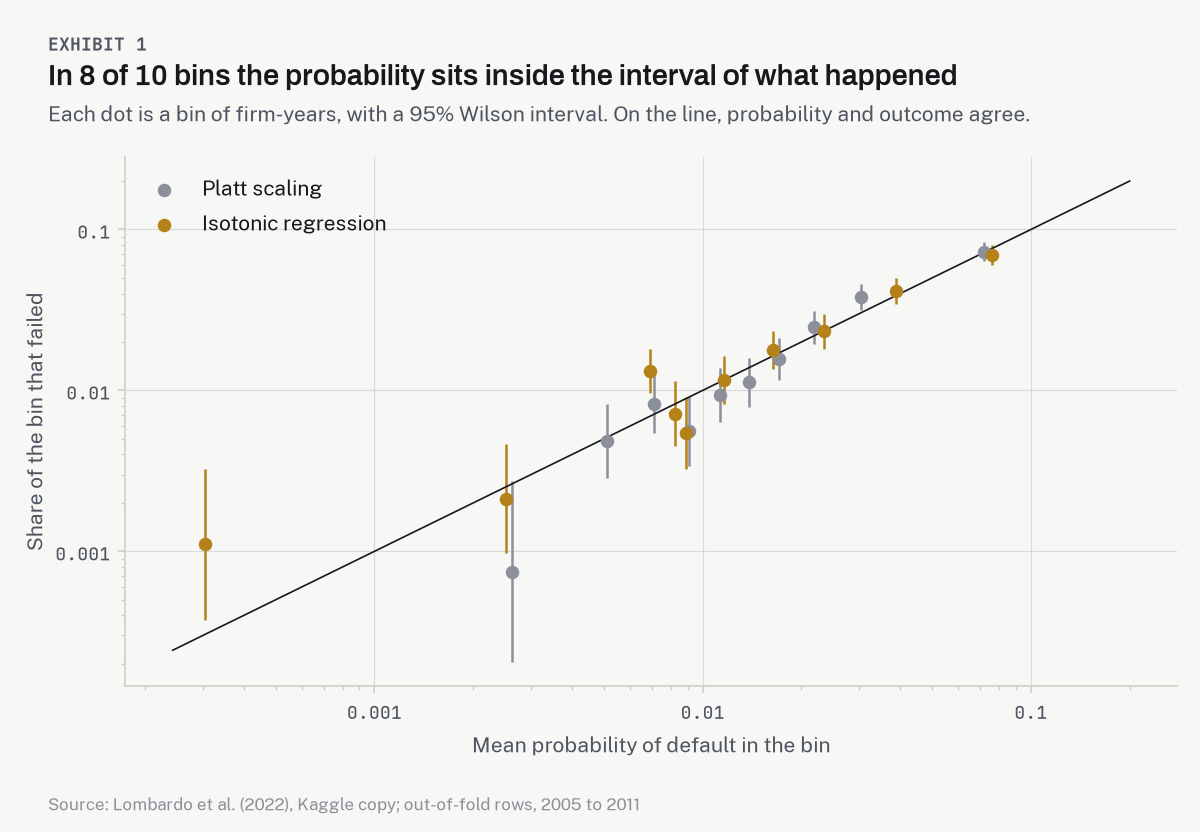

In [7]:
fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 4.2))
tables = {name: reliability_table(chosen_oof["target"], pd_) for name, pd_ in crossed.items()}
for name, table in tables.items():
    color = COLORS["trees"] if name == MAP else viz.MIST
    ax.vlines(table["mean_prob"], table["lo"], table["hi"], color=color, linewidth=1.2)
    ax.scatter(table["mean_prob"], table["rate"], s=30, color=color, zorder=3, label=name)
ends = [min(t["mean_prob"].min() for t in tables.values()) * 0.8, 0.2]
ax.plot(ends, ends, color=viz.INK, linewidth=0.8)
viz.log_axis(ax, "x")
viz.log_axis(ax, "y")
ax.set_xlabel("Mean probability of default in the bin")
ax.set_ylabel("Share of the bin that failed")
ax.legend(frameon=False, loc="upper left")
inside = (tables[MAP]["lo"] <= tables[MAP]["mean_prob"]) & (
    tables[MAP]["mean_prob"] <= tables[MAP]["hi"]
)

store.put("bins_inside", int(inside.sum()))
store.put("n_bins", len(tables[MAP]))
store.put("top_bin_pd", tables[MAP]["mean_prob"].iloc[-1])
store.put("top_bin_rate", tables[MAP]["rate"].iloc[-1])

viz.exhibit(
    fig,
    f"In {int(inside.sum())} of {len(inside)} bins the probability sits inside the interval of what happened",
    "Each dot is a bin of firm-years, with a 95% Wilson interval. On the line, probability and "
    "outcome agree.",
    OOF_SOURCE,
)

**Reading.** In Exhibit 1 a dot on the line is a bin whose probability matched its outcome.
For the chosen map 8 of 10 bins have the probability inside the interval, and the riskiest bin is given 7.6% and failed at 7.0%.

That is the pooled picture, all seven years together.

Q. Does the probability hold year by year?

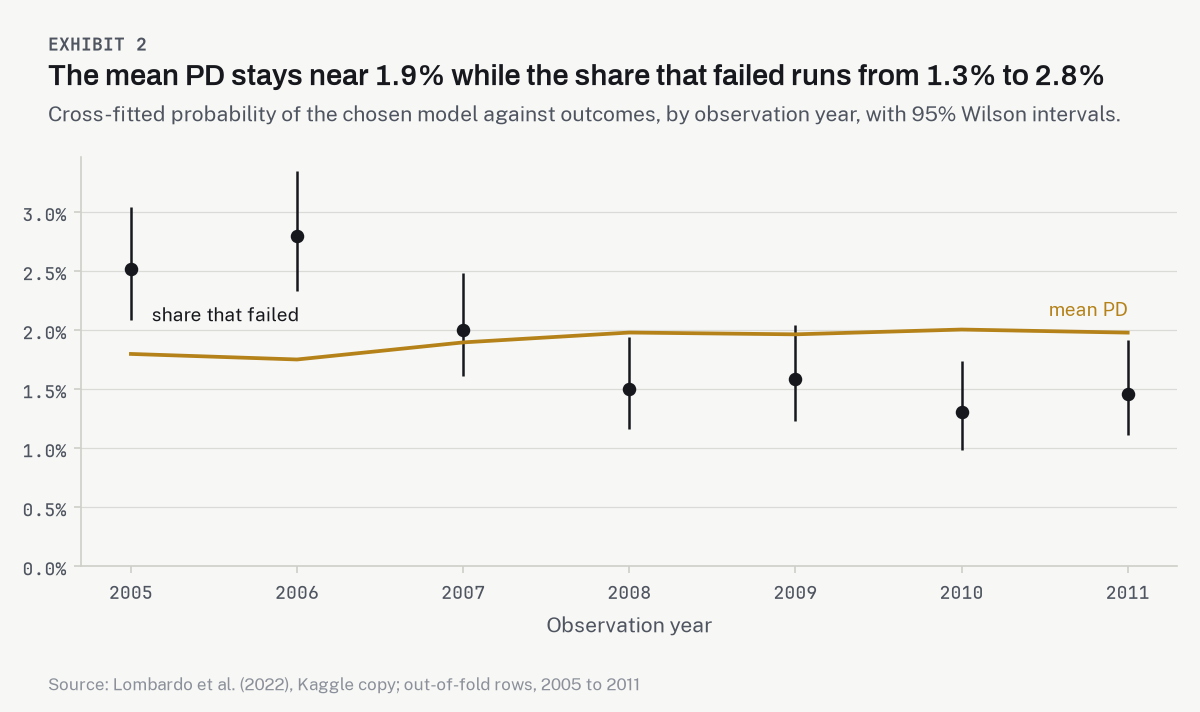

In [8]:
by_year = (
    chosen_oof.assign(pd=pd_oof)
    .groupby("year")
    .agg(
        rows=("target", "size"),
        failed=("target", "sum"),
        predicted=("pd", "mean"),
        rate=("target", "mean"),
    )
)
bounds = np.array(
    [wilson_interval(int(k), int(n)) for k, n in zip(by_year["failed"], by_year["rows"])]
)
own_rows = MAPS[MAP](chosen_oof)(
    chosen_oof["pct"]
)  # the naive check: the map judged on the rows it was fitted on
gap = (by_year["predicted"] - by_year["rate"]).abs()

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.4))
ax.vlines(by_year.index, bounds[:, 0], bounds[:, 1], color=viz.INK, linewidth=1.2)
ax.scatter(by_year.index, by_year["rate"], s=30, color=viz.INK, zorder=3)
ax.plot(by_year.index, by_year["predicted"], color=COLORS["trees"], linewidth=1.8)
ax.annotate("mean PD", (by_year.index[-1], by_year["predicted"].iloc[-1]), xytext=(0, 8),
            textcoords="offset points", color=COLORS["trees"], size=9, ha="right")  # fmt: skip
ax.annotate("share that failed", (by_year.index[0], by_year["rate"].iloc[0]), xytext=(10, -22),
            textcoords="offset points", color=viz.INK, size=9, va="center")  # fmt: skip
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_ylim(0, None)
ax.set_xlabel("Observation year")
ax.grid(axis="x", visible=False)

store.put("pooled_gap", abs(own_rows.mean() - base_rate))
store.put("worst_year", int(gap.idxmax()))
store.put("worst_gap", gap.max())
store.put("worst_predicted", by_year.loc[gap.idxmax(), "predicted"])
store.put("worst_rate", by_year.loc[gap.idxmax(), "rate"])
store.put("flat_low", by_year["predicted"].min())
store.put("flat_high", by_year["predicted"].max())
store.put("rate_low", by_year["rate"].min())
store.put("rate_high", by_year["rate"].max())
# The reading says the probability barely moves while the failure rate halves. Checked here.
assert by_year["predicted"].max() / by_year["predicted"].min() < 1.2
assert by_year["rate"].max() / by_year["rate"].min() > 2

viz.exhibit(
    fig,
    f"The mean PD stays near {base_rate:.1%} while the share that failed runs from "
    f"{by_year['rate'].min():.1%} to {by_year['rate'].max():.1%}",
    "Cross-fitted probability of the chosen model against outcomes, by observation year, with 95% "
    "Wilson intervals.",
    OOF_SOURCE,
)

![Pitfall: Checking a probability on all years at once. Gap between mean PD and failure rate, all years pooled: 0.00%. Largest gap in a single year, map fitted on the other years: 1.04%. A pooled check averages good years against bad ones. A lender lives through them one at a time.](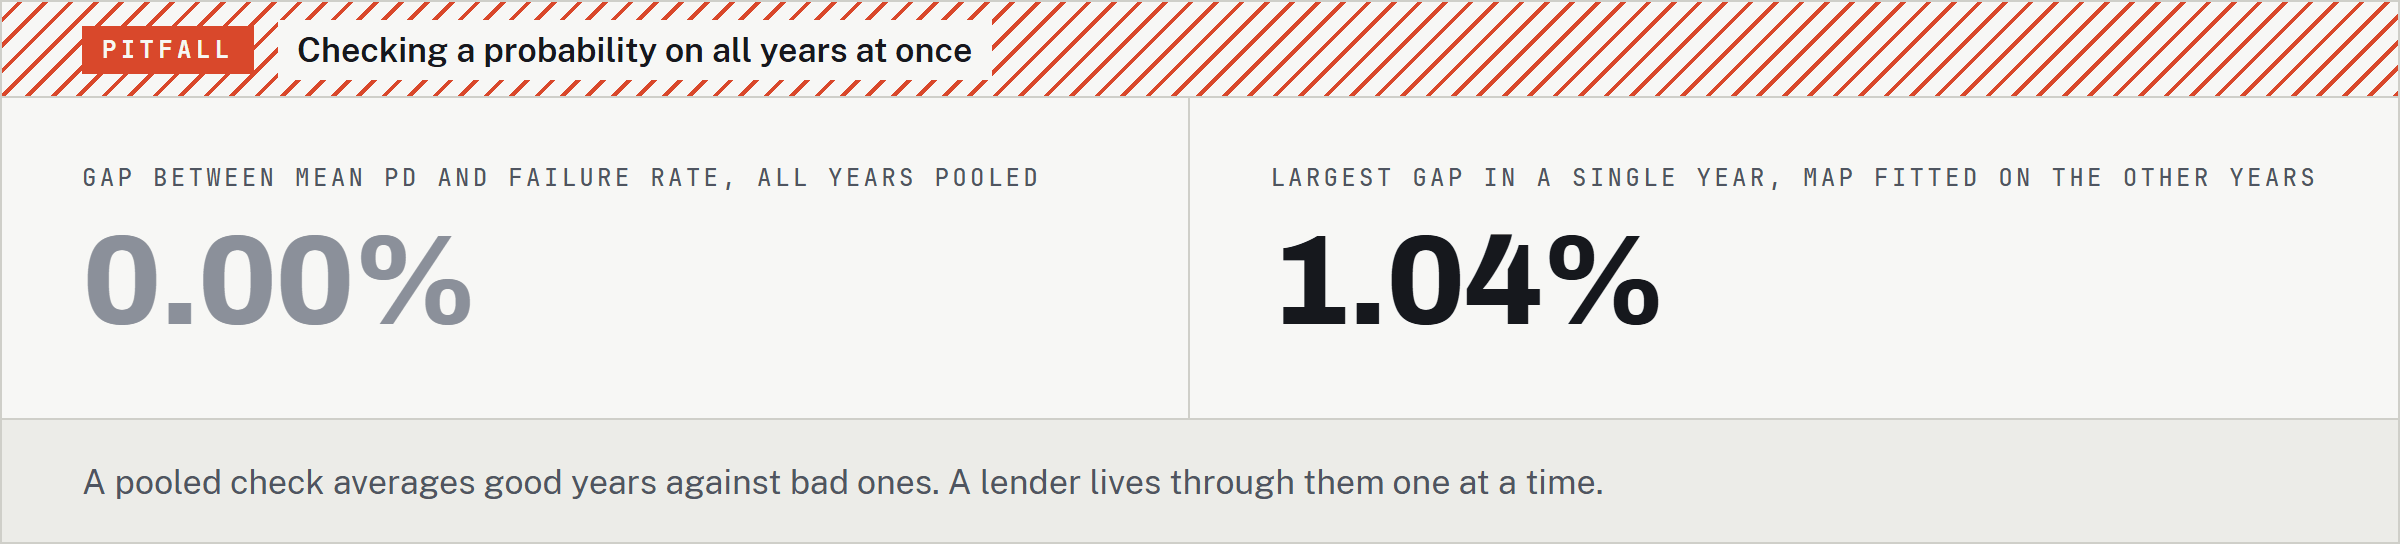)

**Reading.** Exhibit 2 shows what a pooled check hides.
The mean probability stays between 1.8% and 2.0%, and the share that failed runs from 1.3% to 2.8%.

In 2006 the probability says 1.8% and 2.8% failed.
A percentile within the year cannot know whether the year is a good one or a bad one, and no input of this model can tell it.

So this PD is an average over the cycle, right across years and wrong in most single ones.
The casebook carries it forward with that label on it.

**Check.** The file holds accounts and a market value, and no interest rates or credit spreads. Why does that matter for the level of a PD more than for a ranking?

<details>
<summary>Show the answer</summary>

A ranking compares companies with each other in the same year, and a bad year is bad for all of them.
The level is how many of them fail, which moves with the economy.

Nothing in a company's own accounts says where the economy is going, so the level needs information this file does not have.

</details>

**Next, grades.**

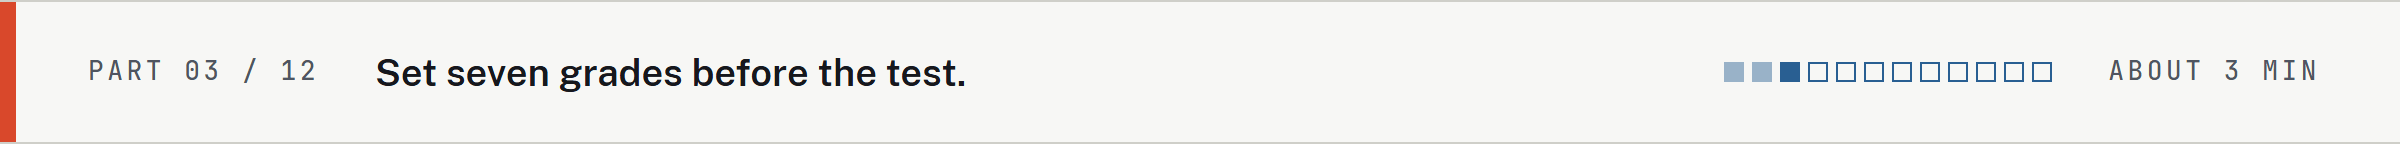

# A Master Scale

A desk rarely works with a probability to four decimals.
It works with **grades**, a short ladder of bands, each with a PD attached.

The scale here has seven grades, set as bands of the percentile within the year.
Grade one is the safest 30% of firm-years, and grade seven the riskiest 2%.

The bands are narrow at the risky end, where the PD changes fastest and a desk looks hardest.
They are fixed here, and the PD of a grade is the mean cross-fitted PD of its firm-years.

Q. Do the grades order the failures on the development years?

,rows,failed,pd,rate,lo,hi
grade,,,,,,
1,8035,29,0.0033,0.0036,0.0025,0.0052
2,8037,75,0.0093,0.0093,0.0075,0.0117
3,5358,106,0.0197,0.0198,0.0164,0.0239
4,2679,104,0.0378,0.0388,0.0321,0.0468
5,1338,87,0.0616,0.0650,0.0530,0.0795
6,804,48,0.0697,0.0597,0.0453,0.0783
7,538,63,0.1190,0.1171,0.0926,0.1470


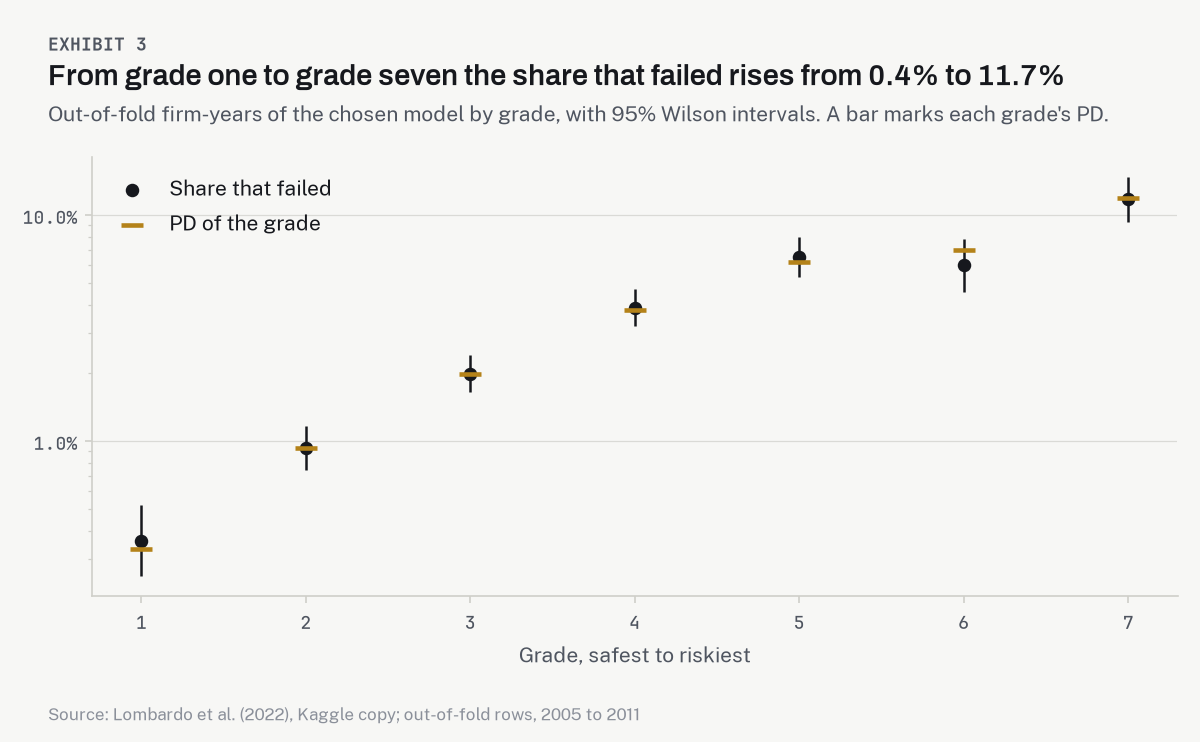

In [9]:
GRADE_EDGES = (
    0.30,
    0.60,
    0.80,
    0.90,
    0.95,
    0.98,
)  # upper ends of grades one to six, as percentiles


def grade_of(pct: pd.Series) -> np.ndarray:
    """The grade, one to seven, of each percentile within its year."""
    return np.digitize(pct, GRADE_EDGES, right=True) + 1


def grade_table(rows: pd.DataFrame, pds: np.ndarray) -> pd.DataFrame:
    """Firm-years, failures, realised rate with its interval, and mean PD, for each grade."""
    table = (
        rows.assign(pd=pds, grade=grade_of(rows["pct"]))
        .groupby("grade")
        .agg(rows=("target", "size"), failed=("target", "sum"), pd=("pd", "mean"))
    )
    bounds = [wilson_interval(int(k), int(n)) for k, n in zip(table["failed"], table["rows"])]
    return table.assign(
        rate=table["failed"] / table["rows"],
        lo=[lo for lo, _ in bounds],
        hi=[hi for _, hi in bounds],
    )


def grade_ladder(table: pd.DataFrame, pds: pd.Series) -> plt.Figure:
    """Realised rate by grade with intervals, against the PD attached to each grade."""
    fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.6))
    ax.vlines(table.index, table["lo"], table["hi"], color=viz.INK, linewidth=1.2)
    ax.scatter(table.index, table["rate"], s=30, color=viz.INK, zorder=3, label="Share that failed")
    ax.scatter(pds.index, pds, s=120, marker="_", color=COLORS["trees"], linewidth=2.2, zorder=4,
               label="PD of the grade")  # fmt: skip
    viz.log_axis(ax, "y")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.set_xlabel("Grade, safest to riskiest")
    ax.legend(frameon=False, loc="upper left")
    ax.grid(axis="x", visible=False)
    return fig


grades_dev = grade_table(chosen_oof, pd_oof)
GRADE_PD = grades_dev["pd"]
step_up = grades_dev["rate"].diff().iloc[1:] > 0
# The reading says the rate rises with the grade except from five to six, where the intervals overlap.
assert list(step_up.index[~step_up]) == [6]
assert grades_dev.loc[6, "hi"] > grades_dev.loc[5, "lo"]

store.put("band_1", GRADE_EDGES[0])
store.put("band_7", 1 - GRADE_EDGES[-1])
store.put("grade_1_rate", grades_dev.loc[1, "rate"])
store.put("grade_7_rate", grades_dev.loc[7, "rate"])
store.put("grade_5_rate", grades_dev.loc[5, "rate"])
store.put("grade_6_rate", grades_dev.loc[6, "rate"])
store.put("grade_7_pd", GRADE_PD[7])

viz.exhibit(
    grade_ladder(grades_dev, GRADE_PD),
    f"From grade one to grade seven the share that failed rises from {grades_dev.loc[1, 'rate']:.1%} "
    f"to {grades_dev.loc[7, 'rate']:.1%}",
    "Out-of-fold firm-years of the chosen model by grade, with 95% Wilson intervals. A bar marks "
    "each grade's PD.",
    OOF_SOURCE,
)
grades_dev.round(4)

**Reading.** In Exhibit 3 the share that failed climbs from 0.4% in grade one to 11.7% in grade seven.
One step is out of order: grade six failed at 6.0% and grade five at 6.5%, with intervals that overlap.

The two are kept as separate grades, since merging them now would be a choice made after the result.

The map, the bands, and the PD of each grade are now fixed.
**Next, the holdout.**

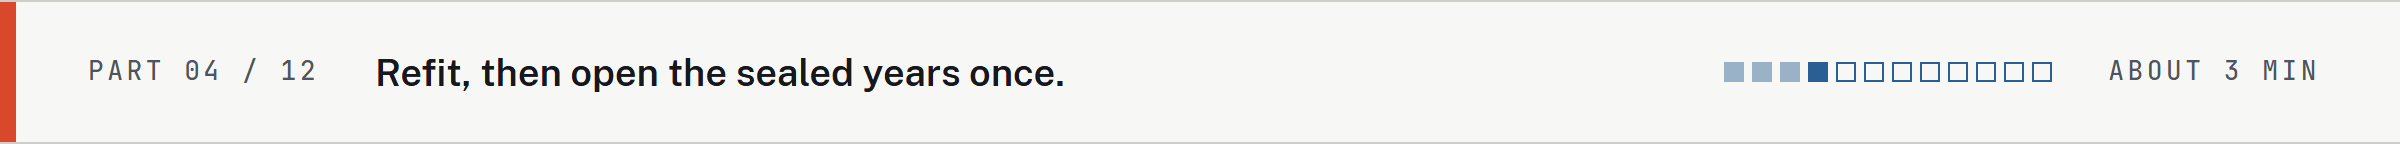

# Opening the Holdout

First the seven models are fitted for the last time.
Each recipe is read from the record, and each is fitted on every development row, 1999 to 2011.

The number of boosting rounds comes from the walk-forward, as Chapter 5 left it.
The network chooses its epochs as it did in every fold, by stopping on the last two training years, and is then fitted on all of them.

Q. How is each model fitted?

In [10]:
def fit_classic(train: pd.DataFrame, spec: dict) -> Callable:
    return lambda rows: -altman_z(rows).to_numpy()  # a low Z is the risky end


def fit_logistic(train: pd.DataFrame, spec: dict) -> Callable:
    prepare, *_ = fit_prepare(train, spec["features"])
    model = make_pipeline(
        StandardScaler(), LogisticRegression(C=spec.get("C", np.inf), max_iter=2000)
    )
    model.fit(prepare(train), train["target"])
    return lambda rows: model.predict_proba(prepare(rows))[:, 1]


def fit_trees(train: pd.DataFrame, spec: dict) -> Callable:
    prepare, *_ = fit_prepare(train, spec["features"], impute=False)
    model = XGBClassifier(
        n_estimators=spec["rounds"], n_jobs=1, random_state=SEED, **spec["params"]
    )
    model.fit(prepare(train), train["target"])
    score = lambda rows: model.predict_proba(prepare(rows))[:, 1]
    score.model, score.prepare = model, prepare  # kept for the part that explains the score
    return score


def fit_network(train: pd.DataFrame, spec: dict) -> Callable:
    columns = spec["features"]
    scale = QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEED)
    scale.fit(train[columns])
    blanks = [name for name in columns if train[name].isna().any()]

    def inputs(rows: pd.DataFrame) -> torch.Tensor:
        bell = pd.DataFrame(scale.transform(rows[columns]), columns=columns, index=rows.index)
        flags = {f"{name}_blank": rows[name].isna().astype(float) for name in blanks}
        return torch.tensor(bell.fillna(0.0).assign(**flags).to_numpy(dtype=np.float32))

    data = (
        inputs(train),
        torch.tensor(train["target"].to_numpy(dtype=np.float32)),
        torch.ones(len(train)),
    )
    stop = torch.tensor((train["year"] > train["year"].max() - spec["stop_years"]).to_numpy())
    members = []
    for seed in spec["seeds"]:
        seed_everything(seed)
        make = lambda: TabularNet(data[0].shape[1], spec["hidden"], spec["dropout"])
        early, held = tuple(part[~stop] for part in data), tuple(part[stop] for part in data)
        stopped = train_net(make(), early, held, seed=seed, **spec["settings"])
        seed_everything(seed)
        model = make()
        train_net(
            model, data, None, seed=seed, **{**spec["settings"], "epochs": stopped["best_epoch"]}
        )
        members.append(model)
    return lambda rows: np.mean([predict(model, inputs(rows)) for model in members], axis=0)


FIT = {
    "published score": fit_classic,
    "logistic regression": fit_logistic,
    "gradient boosting": fit_trees,
    "tabular network": fit_network,
}
BLENDS = {name: spec["members"] for name, spec in frozen.items() if "members" in spec}

# Seven models on every development row. The network takes about a minute.
fitted = {name: FIT[spec["kind"]](dev, spec) for name, spec in frozen.items() if name not in BLENDS}


def score_rows(rows: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Every rung's score for `rows`, ranked within each year, in the form the ladder keeps."""

    def ranked(scores: np.ndarray) -> pd.DataFrame:
        table = rows[[*KEYS, "target"]].assign(score=scores)
        return table.assign(pct=within_year_percentile(table["score"], table["year"]))

    scored = {name: ranked(score(rows)) for name, score in fitted.items()}
    for name, members in BLENDS.items():
        scored[name] = ranked(np.mean([scored[member]["pct"] for member in members], axis=0))
    return {name: scored[name] for name in frozen}


# The final map from percentile to PD, fitted on all seven walk-forward years.
to_pd = MAPS[MAP](chosen_oof)

store.put("n_dev", len(dev))
store.put("dev_failures", int(dev["target"].sum()))
len(fitted), list(BLENDS)

(6, ['Blend, trees and network'])

**Reading.** Six models are fitted on 55,524 firm-years with 840 failures, and the blend is the mean of two of them.
Nothing in that cell looked at a year after 2011.

The next cell is the only one in the casebook that does.
The holdout is the observation years 2014 to 2016, and the two years between are left out because their labels overlap the last development years.

**Predict 1.** The chosen model scored 0.776 on the walk-forward, and that number helped to choose it. Will its ROC-AUC on the holdout be higher, lower, or about the same?

Q. What does the holdout say?

In [11]:
sealed = holdout(features, unseal=True).reset_index(drop=True)
verdict = score_rows(sealed)
board = scoreboard(verdict).set_index("model")
primary = paired_table(
    {CLASSIC: verdict[CLASSIC], CHOSEN: verdict[CHOSEN]}, [CLASSIC, CHOSEN]
).iloc[0]
top = board.loc[CHOSEN]

store.put("n_holdout", len(sealed))
store.put("holdout_failures", int(sealed["target"].sum()))
store.put("holdout_rate", sealed["target"].mean())
store.put("holdout_auc", top["roc_auc"])
store.put("holdout_auc_low", top["roc_auc_lo"])
store.put("holdout_auc_high", top["roc_auc_hi"])
store.put("holdout_capture_5", top["capture_5"])
store.put("holdout_capture_5_low", top["capture_5_lo"])
store.put("holdout_capture_5_high", top["capture_5_hi"])
store.put("holdout_lift_5", top["lift_5"])
store.put("classic_auc", board.loc[CLASSIC, "roc_auc"])
store.put("primary_step", primary["roc_auc_diff"])
store.put("primary_step_low", primary["roc_auc_diff_lo"])
store.put("primary_step_high", primary["roc_auc_diff_hi"])
# The reading says the holdout score is above the walk-forward one and the primary step is clear of zero.
assert top["roc_auc"] > walked_board["roc_auc"]
assert primary["roc_auc_diff_lo"] > 0

board[
    ["rows", "positives", "roc_auc", "roc_auc_lo", "roc_auc_hi", "ap", "capture_5", "lift_5"]
].round(3)

,rows,positives,roc_auc,roc_auc_lo,roc_auc_hi,ap,capture_5,lift_5
model,,,,,,,,
Altman Z,9954,160,0.716,0.676,0.753,0.029,0.056,1.124
"Five ratios, refitted",9954,160,0.743,0.705,0.780,0.035,0.062,1.249
"All ratios, logistic",9954,160,0.779,0.733,0.817,0.063,0.244,4.872
"All ratios, trees",9954,160,0.815,0.779,0.850,0.119,0.356,7.121
Plus history,9954,160,0.828,0.795,0.861,0.125,0.331,6.621
"Network, all ratios",9954,160,0.814,0.777,0.851,0.142,0.375,7.495
"Blend, trees and network",9954,160,0.821,0.785,0.855,0.152,0.375,7.495


**Reading.** The chosen model scores 0.815 on the holdout, with an interval from 0.779 to 0.850.
That is above its walk-forward score, which answers Predict 1.

It does not show that the walk-forward score was free of flattery: the two samples differ in more than the model, as the next part says.

The primary comparison is settled.
The chosen model is ahead of the published score by 0.099, with an interval from 0.063 to 0.136.

The holdout has 9,954 firm-years and 160 failures.
The model's top twentieth of each year holds 35.6% of them, with an interval from 27.0% to 43.6%.

**Next, the other rungs.**

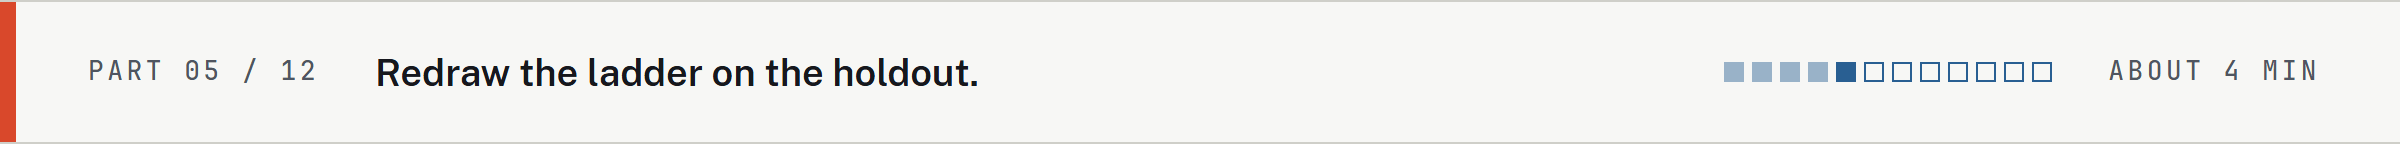

# The Ladder

The ladder asked where the predictive power comes from, one rung at a time.
On the walk-forward it had 26,789 rows and 512 failures to answer with.

The holdout has 160 failures.
That is enough to order models that are far apart, and too few to settle a step of a hundredth.

**Predict 2.** On the walk-forward, adding history to the trees was a step down. Will the holdout agree?

Q. What does each rung score on the holdout, and what does each add to the one below?

,walk-forward,holdout,holdout minus walk-forward
Altman Z,0.704,0.716,0.012
"Five ratios, refitted",0.662,0.743,0.081
"All ratios, logistic",0.750,0.779,0.029
"All ratios, trees",0.776,0.815,0.040
Plus history,0.750,0.828,0.079
"Network, all ratios",0.742,0.814,0.072
"Blend, trees and network",0.771,0.821,0.050


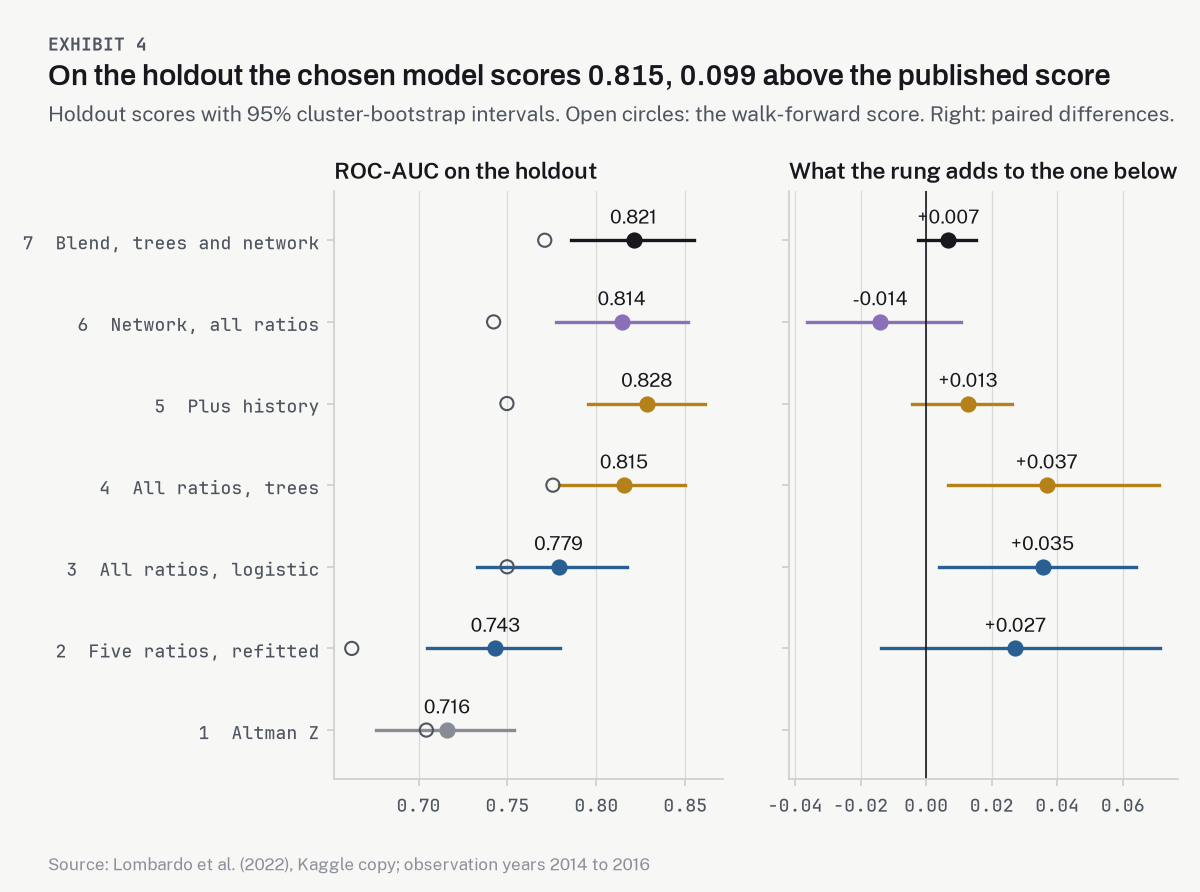

In [12]:
steps = paired_table(verdict, list(verdict)).set_index("model")
walk_board = pd.Series(
    {name: roc_auc_score(oof["target"], oof["pct"]) for name, oof in ladder.items()}
)
both = pd.DataFrame({"walk-forward": walk_board, "holdout": board["roc_auc"]})
both["holdout minus walk-forward"] = both["holdout"] - both["walk-forward"]

KINDS = ("classic", "logistic", "logistic", "trees", "trees", "networks", "blend")
fig, (level, change) = plt.subplots(1, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 4.6), sharey=True)
place = np.arange(len(verdict))
for y_at, (name, row), kind in zip(place, board.iterrows(), KINDS):
    level.plot(
        [row["roc_auc_lo"], row["roc_auc_hi"]], [y_at, y_at], color=COLORS[kind], linewidth=1.6
    )
    level.scatter(row["roc_auc"], y_at, s=46, color=COLORS[kind], zorder=3)
    level.scatter(walk_board[name], y_at, s=40, facecolor="none", edgecolor=viz.SLATE, zorder=2)
    level.annotate(f"{row['roc_auc']:.3f}", (row["roc_auc"], y_at), xytext=(0, 8),
                   textcoords="offset points", ha="center", size=9)  # fmt: skip
for y_at, (name, row), kind in zip(place[1:], steps.iterrows(), KINDS[1:]):
    change.plot([row["roc_auc_diff_lo"], row["roc_auc_diff_hi"]], [y_at, y_at], color=COLORS[kind],
                linewidth=1.6)  # fmt: skip
    change.scatter(row["roc_auc_diff"], y_at, s=46, color=COLORS[kind], zorder=3)
    change.annotate(f"{row['roc_auc_diff']:+.3f}", (row["roc_auc_diff"], y_at), xytext=(0, 8),
                    textcoords="offset points", ha="center", size=9)  # fmt: skip
change.axvline(0, color=viz.INK, linewidth=0.8)
level.set_yticks(place, [f"{k + 1}  {name}" for k, name in enumerate(verdict)])
level.set_ylim(-0.6, len(verdict) - 0.4)
level.set_title("ROC-AUC on the holdout")
level.xaxis.set_major_locator(MultipleLocator(0.05))
change.set_title("What the rung adds to the one below")
for ax in (level, change):
    ax.grid(axis="y", visible=False)

settled = steps["roc_auc_diff_lo"].gt(0) | steps["roc_auc_diff_hi"].lt(0)
store.put("walk_failures", int(chosen_oof["target"].sum()))
store.put("n_settled", int(settled.sum()))
store.put("n_steps", len(steps))
store.put("best_rung", board["roc_auc"].idxmax())
store.put("best_rung_auc", board["roc_auc"].max())
store.put("history_step", steps.loc["Plus history", "roc_auc_diff"])
store.put("history_step_low", steps.loc["Plus history", "roc_auc_diff_lo"])
store.put("history_step_high", steps.loc["Plus history", "roc_auc_diff_hi"])
store.put("shift_low", both["holdout minus walk-forward"].min())
store.put("shift_high", both["holdout minus walk-forward"].max())
# The readings say: every rung is higher than on the walk-forward, the broad order holds, history's
# step holds zero, the chosen model is not the highest rung, and two steps are clear of zero.
assert both["holdout minus walk-forward"].min() > 0
assert board.loc[CLASSIC, "roc_auc"] < board.loc["All ratios, logistic", "roc_auc"] < top["roc_auc"]
assert steps.loc["Plus history", "roc_auc_diff_lo"] < 0 < steps.loc["Plus history", "roc_auc_diff"]
assert board["roc_auc"].idxmax() != CHOSEN
assert settled.sum() == 2
REFIT = "Five ratios, refitted"
assert steps.loc[REFIT, "roc_auc_diff_lo"] < 0 < steps.loc[REFIT, "roc_auc_diff"]
store.put("refit_step", steps.loc[REFIT, "roc_auc_diff"])

viz.exhibit(
    fig,
    f"On the holdout the chosen model scores {top['roc_auc']:.3f}, {primary['roc_auc_diff']:.3f} above the "
    "published score",
    "Holdout scores with 95% cluster-bootstrap intervals. Open circles: the walk-forward score. "
    "Right: paired differences.",
    f"{SOURCE}; observation years {HOLDOUT[0]} to {HOLDOUT[1]}",
    save_as="ladder",
)
both.round(3)

**Reading.** Exhibit 4 is the central picture of the casebook.
The broad order of the walk-forward holds: the published score at the foot, the logistic regression on every ratio above it, the trees above that.

Every rung scores higher here than on the walk-forward, the open circles, by 0.012 to 0.081.
The two samples differ in more than the models, with no recession in the holdout and more years to train on, so levels are not compared across them.

The fine order does not hold.
History is a step up here, 0.013, with an interval from -0.004 to 0.026 that holds zero, so Predict 2 has no firm answer.

That fits what Chapter 5 saw fold by fold: history lost in the folds that trained on the file's first years and gained in the later ones, and the final model trains on all of them.
The refit of Altman's five ratios, a step down in Chapter 4, is a step of 0.027 here, with an interval that holds zero as well.

The highest rung on the holdout is "Plus history", at 0.828, and it is not the model chosen.
Only 2 of the 6 steps have an interval clear of zero.

**Check.** The rung with history scores highest on the holdout. Why not switch to it now?

<details>
<summary>Show the answer</summary>

The holdout is a test only while nothing is chosen on it.
Pick its winner and it becomes one more validation window, with nothing left to test the pick.

The margin is also inside its interval, so the winner here may be chance.

</details>

**Next, what a desk would have found.**

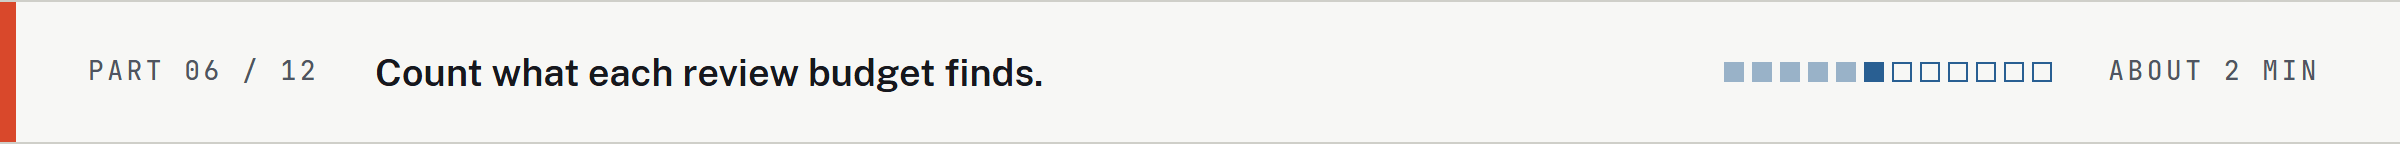

# Capture Curves

A desk does not review a ROC-AUC.
It reviews a share of its names each year, and what matters is how many of the failures were on that list.

Q. How many failures does each review budget find, and how sure is that?

,failures found,low,high,lift
"Altman Z, top 1%",0.006,0.000,0.020,0.622
"All ratios, trees, top 1%",0.150,0.097,0.209,14.931
"Altman Z, top 5%",0.056,0.019,0.104,1.124
"All ratios, trees, top 5%",0.356,0.270,0.436,7.121
"Altman Z, top 10%",0.119,0.062,0.187,1.188
"All ratios, trees, top 10%",0.475,0.383,0.556,4.752


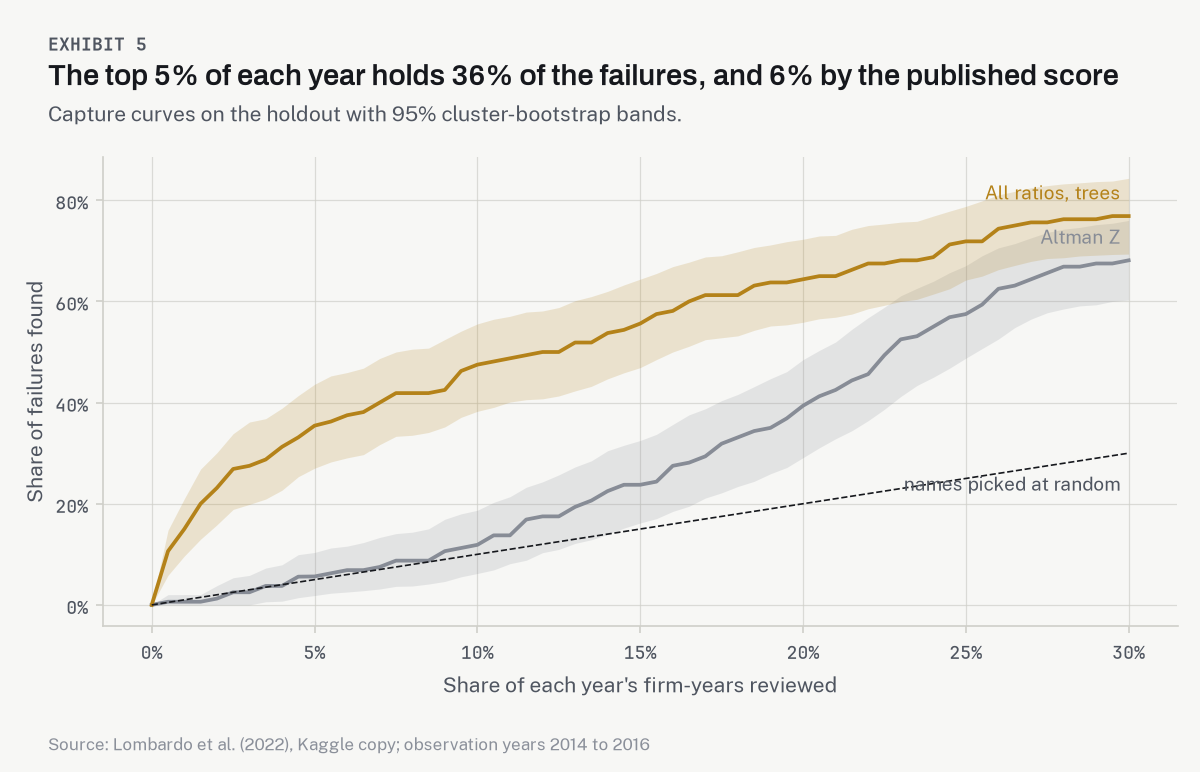

In [13]:
def capture_band(oof: pd.DataFrame, grid: np.ndarray) -> np.ndarray:
    """The 95% band of the capture curve on `grid`, resampling whole companies."""
    y, pct = oof["target"].to_numpy(), oof["pct"].to_numpy()
    curves = []
    for rows in company_resamples(y, oof["company_name"], N_BOOT, SEED):
        reviewed, captured = capture_curve(y[rows], pct[rows])
        curves.append(np.interp(grid, reviewed, captured))
    return np.percentile(curves, [2.5, 97.5], axis=0)


N_BOOT = 1000
grid = np.linspace(0, 0.3, 61)
fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.8))
for name, kind in ((CLASSIC, "classic"), (CHOSEN, "trees")):
    reviewed, captured = capture_curve(verdict[name]["target"], verdict[name]["pct"])
    low, high = capture_band(verdict[name], grid)
    ax.fill_between(grid, low, high, color=COLORS[kind], alpha=0.18, linewidth=0)
    ax.plot(grid, np.interp(grid, reviewed, captured), color=COLORS[kind], linewidth=1.8)
    ax.annotate(name, (grid[-1], np.interp(grid[-1], reviewed, captured)), xytext=(-4, 8),
                textcoords="offset points", color=COLORS[kind], size=9, ha="right")  # fmt: skip
ax.plot(grid, grid, color=viz.INK, linewidth=0.8, linestyle="--")
ax.annotate("names picked at random", (grid[-1], grid[-1]), xytext=(-4, -18),
            textcoords="offset points", color=viz.SLATE, size=9, ha="right")  # fmt: skip
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Share of each year's firm-years reviewed")
ax.set_ylabel("Share of failures found")

budgets = pd.DataFrame(
    {
        f"{name}, top {share}%": board.loc[
            name,
            [f"capture_{share}", f"capture_{share}_lo", f"capture_{share}_hi", f"lift_{share}"],
        ].to_numpy()
        for share in (1, 5, 10)
        for name in (CLASSIC, CHOSEN)
    },
    index=["failures found", "low", "high", "lift"],
).T
for share in (1, 10):
    store.put(f"holdout_capture_{share}", top[f"capture_{share}"])
store.put("classic_capture_5", board.loc[CLASSIC, "capture_5"])
# The desk's list is every firm-year above the 95th percentile of its year, the list the case files use.
on_list = verdict[CHOSEN]["pct"] > 0.95
found = int((on_list & (verdict[CHOSEN]["target"] == 1)).sum())
# The list finds the same failures as the capture rate at the middle budget. Checked here.
assert found == round(top["capture_5"] * sealed["target"].sum())
store.put("found_5", found)
store.put("reviewed_5", int(on_list.sum()))

viz.exhibit(
    fig,
    f"The top 5% of each year holds {top['capture_5']:.0%} of the failures, and "
    f"{board.loc[CLASSIC, 'capture_5']:.0%} by the published score",
    "Capture curves on the holdout with 95% cluster-bootstrap bands.",
    f"{SOURCE}; observation years {HOLDOUT[0]} to {HOLDOUT[1]}",
)
budgets.round(3)

**Reading.** In Exhibit 5 the chosen model's curve climbs at once.
The top hundredth of each year holds 15.0% of the failures, the top twentieth 35.6%, and the top tenth 47.5%.

A desk that read the top twentieth of each year, 500 of the 9,954 firm-years, would have had 57 of the 160 failures on its list.

The published score finds 5.6% at the same budget, which is no better than names picked at random.
Its ROC-AUC comes from ordering the broad middle, and it fails where a desk looks, at the top.

**Next, the probabilities.**

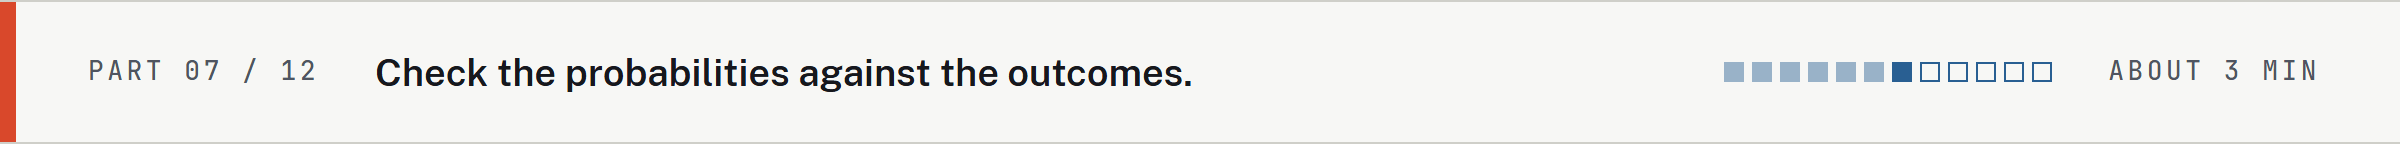

# Did the Probabilities Hold

The map and the grades were fixed before the holdout was opened.
Each holdout firm-year now gets its PD from its percentile, and its grade from the same bands.

Q. Did each grade fail at the rate attached to it?

      predicted    rate
year                   
2014     0.0191  0.0170
2015     0.0191  0.0142
2016     0.0191  0.0171


,rows,failed,pd,rate,lo,hi
grade,,,,,,
1,2985,3,0.0034,0.0010,0.0003,0.0030
2,2986,24,0.0093,0.0080,0.0054,0.0119
3,1990,30,0.0197,0.0151,0.0106,0.0214
4,995,27,0.0379,0.0271,0.0187,0.0392
5,498,19,0.0620,0.0382,0.0246,0.0588
6,299,20,0.0694,0.0669,0.0437,0.1011
7,201,37,0.1189,0.1841,0.1366,0.2434


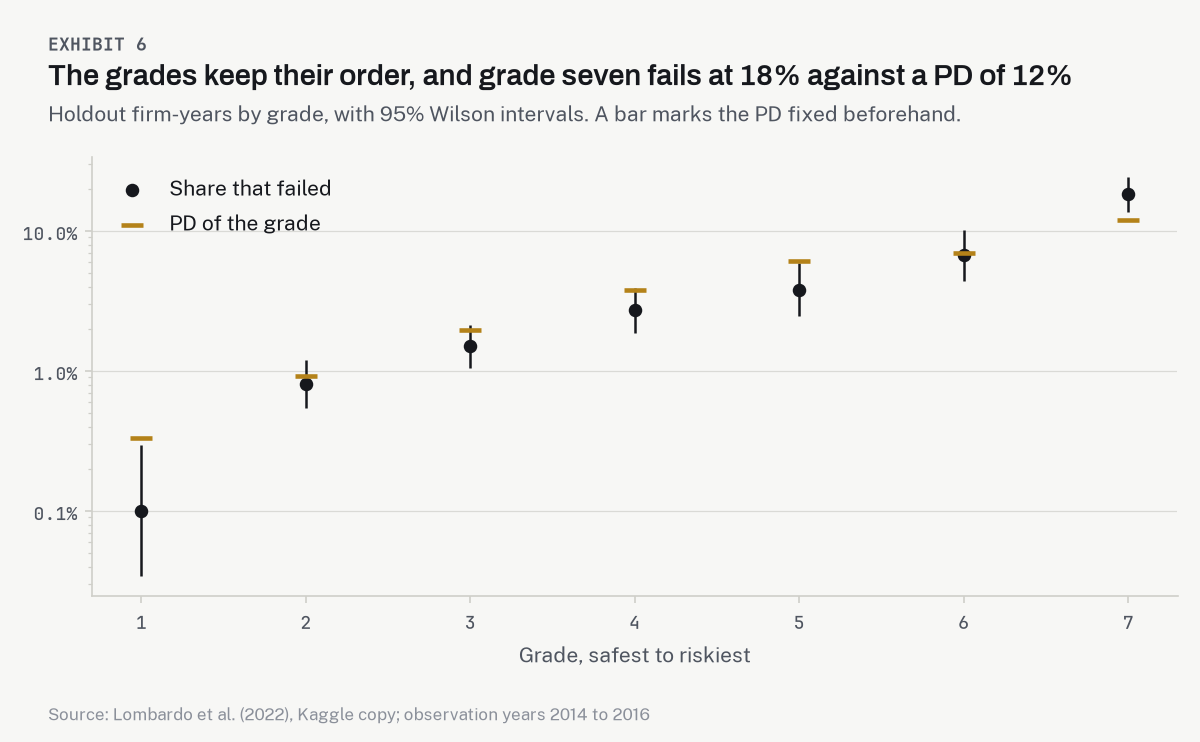

In [14]:
pd_holdout = to_pd(verdict[CHOSEN]["pct"])
grades_holdout = grade_table(verdict[CHOSEN], pd_holdout)
inside_grade = (grades_holdout["lo"] <= GRADE_PD) & (GRADE_PD <= grades_holdout["hi"])
years_holdout = (
    verdict[CHOSEN]
    .assign(pd=pd_holdout)
    .groupby("year")
    .agg(predicted=("pd", "mean"), rate=("target", "mean"))
)
brier_holdout = np.mean((pd_holdout - sealed["target"]) ** 2)
brier_flat = np.mean((sealed["target"].mean() - sealed["target"]) ** 2)

store.put("mean_pd_holdout", pd_holdout.mean())
store.put("grades_inside", int(inside_grade.sum()))
store.put("grade_1_holdout", grades_holdout.loc[1, "rate"])
store.put("grade_7_holdout", grades_holdout.loc[7, "rate"])
store.put("grade_7_pd_fixed", GRADE_PD[7])
store.put("brier_holdout", brier_holdout)
store.put("brier_holdout_flat", brier_flat)
# The readings say: the rate rises at every grade, grade seven fails above its PD, the mean PD is
# above the failure rate in each year, and the map beats one probability for all.
assert (grades_holdout["rate"].diff().iloc[1:] > 0).all()
assert grades_holdout.loc[7, "lo"] > GRADE_PD[7]
assert (years_holdout["predicted"] > years_holdout["rate"]).all()
assert brier_holdout < brier_flat

print(years_holdout.round(4))
viz.exhibit(
    grade_ladder(grades_holdout, GRADE_PD),
    f"The grades keep their order, and grade seven fails at {grades_holdout.loc[7, 'rate']:.0%} "
    f"against a PD of {GRADE_PD[7]:.0%}",
    "Holdout firm-years by grade, with 95% Wilson intervals. A bar marks the PD fixed beforehand.",
    f"{SOURCE}; observation years {HOLDOUT[0]} to {HOLDOUT[1]}",
)
grades_holdout.round(4)

**Reading.** The grades held their order: in Exhibit 6 the share that failed rises at every step, from 0.1% to 18.4%.
The levels held less well, and the PD fixed beforehand sits inside the interval for 4 of the seven grades.

Grade seven failed at 18.4% against a PD of 11.9%, and the middle grades failed less often than their PDs said.
The model separated the riskiest firm-years more sharply here than on the walk-forward, which is the higher ROC-AUC seen from another side.

Across all firm-years the mean PD is 1.9% and 1.6% failed, and in each of the three years the PD was the higher of the two.
The Brier score is 0.01516, against 0.01582 for one probability given to every row.

**Next, the same result cut several ways.**

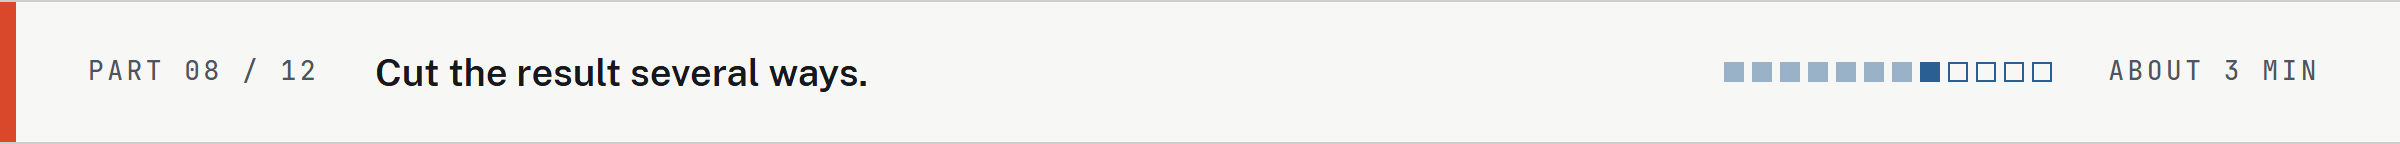

# Robustness

One number on one sample is a thin result.
The same score is now read on parts of the holdout, and against two other labels.

The cuts were listed before the holdout was opened: companies the model trained on and companies it never saw, each year alone, the sample without its **unconfirmed** failures, and failure within one year and within three.
An unconfirmed failure is one whose last filing is in the file's last year, so no later row confirms that it stopped.

Q. Does the result hold in each cut?

,rows,failures,roc_auc,low,high
cut,,,,,
All holdout firm-years,9954,160,0.815,0.779,0.850
Companies seen in development,7644,131,0.841,0.804,0.876
Companies never seen,2310,29,0.722,0.601,0.832
Observation year 2014,3471,59,0.809,0.758,0.856
Observation year 2015,3321,47,0.835,0.774,0.888
Observation year 2016,3162,54,0.806,0.738,0.865
Without unconfirmed failures,9919,125,0.834,0.792,0.873
Failure within one year,9954,80,0.850,0.813,0.886
Failure within three years,6792,156,0.792,0.748,0.832


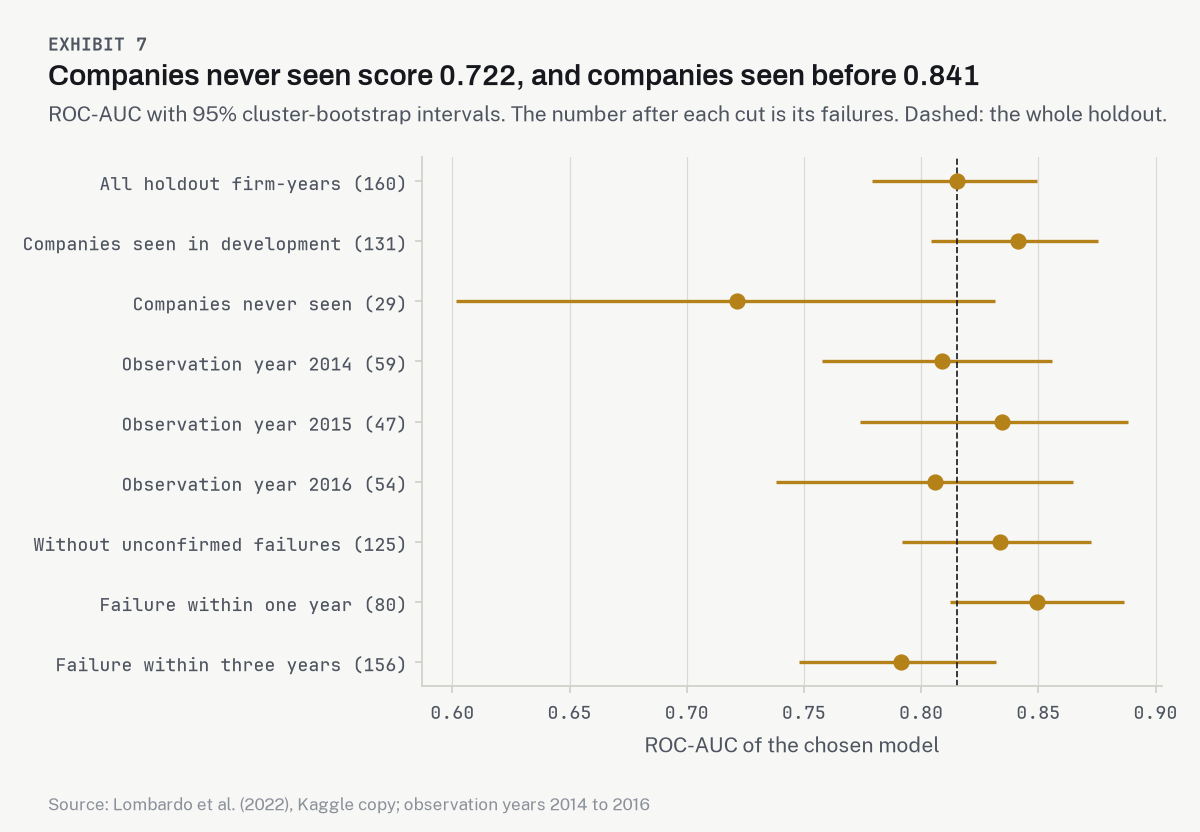

In [15]:
hold = verdict[CHOSEN]
seen = sealed["company_name"].isin(dev["company_name"]).to_numpy()
unconfirmed = ((sealed["target"] == 1) & (sealed["last_year"] == PANEL_END)).to_numpy()
cuts = {"All holdout firm-years": (np.ones(len(sealed), dtype=bool), sealed["target"])}
cuts["Companies seen in development"] = (seen, sealed["target"])
cuts["Companies never seen"] = (~seen, sealed["target"])
for year in range(HOLDOUT[0], HOLDOUT[1] + 1):
    cuts[f"Observation year {year}"] = ((sealed["year"] == year).to_numpy(), sealed["target"])
cuts["Without unconfirmed failures"] = (~unconfirmed, sealed["target"])
cuts["Failure within one year"] = (np.ones(len(sealed), dtype=bool), sealed["target_1"])
cuts["Failure within three years"] = (sealed["target_3"].notna().to_numpy(), sealed["target_3"])

rows = []
for name, (keep, outcome) in cuts.items():
    y, pct = outcome[keep].to_numpy().astype(int), hold.loc[keep, "pct"].to_numpy()
    low, high, _ = cluster_bootstrap_ci(
        y, pct, sealed.loc[keep, "company_name"].to_numpy(), roc_auc_score
    )
    rows.append({"cut": name, "rows": int(keep.sum()), "failures": int(y.sum()),
                 "roc_auc": roc_auc_score(y, pct), "low": low, "high": high})  # fmt: skip
robust = pd.DataFrame(rows).set_index("cut")

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 4.2))
place = np.arange(len(robust))[::-1]
ax.hlines(place, robust["low"], robust["high"], color=COLORS["trees"], linewidth=1.6)
ax.scatter(robust["roc_auc"], place, s=46, color=COLORS["trees"], zorder=3)
ax.axvline(robust["roc_auc"].iloc[0], color=viz.INK, linewidth=0.8, linestyle="--")
ax.set_yticks(place, [f"{name} ({failures})" for name, failures in robust["failures"].items()])
ax.set_xlabel("ROC-AUC of the chosen model")
ax.grid(axis="y", visible=False)

# The reading says every company never seen first filed after the development years. Checked here.
first_filed = features.groupby("company_name")["year"].min()
assert (first_filed[sealed.loc[~seen, "company_name"]] > DEV_END).all()
store.put("seen_share", seen.mean())
store.put("unseen_auc", robust.loc["Companies never seen", "roc_auc"])
store.put("unseen_low", robust.loc["Companies never seen", "low"])
store.put("unseen_high", robust.loc["Companies never seen", "high"])
store.put("seen_auc", robust.loc["Companies seen in development", "roc_auc"])
store.put("unseen_failures", int(robust.loc["Companies never seen", "failures"]))
store.put("n_unconfirmed", int(unconfirmed.sum()))
store.put("confirmed_auc", robust.loc["Without unconfirmed failures", "roc_auc"])
store.put("one_year_auc", robust.loc["Failure within one year", "roc_auc"])
store.put("three_year_auc", robust.loc["Failure within three years", "roc_auc"])
store.put("year_auc_low", robust.filter(like="Observation year", axis=0)["roc_auc"].min())
store.put("year_auc_high", robust.filter(like="Observation year", axis=0)["roc_auc"].max())
store.put(
    "cuts_holding",
    int(((robust["low"] <= top["roc_auc"]) & (top["roc_auc"] <= robust["high"])).sum()),
)
store.put("n_cuts", len(robust))
# The readings say: every cut's interval holds the whole-holdout score, never-seen companies score
# lower than seen ones, and the score does not fall without the unconfirmed failures.
assert ((robust["low"] <= top["roc_auc"]) & (top["roc_auc"] <= robust["high"])).all()
assert (
    robust.loc["Companies never seen", "roc_auc"]
    < robust.loc["Companies seen in development", "roc_auc"]
)
assert robust.loc["Without unconfirmed failures", "roc_auc"] > top["roc_auc"]

viz.exhibit(
    fig,
    f"Companies never seen score {robust.loc['Companies never seen', 'roc_auc']:.3f}, and companies "
    f"seen before {robust.loc['Companies seen in development', 'roc_auc']:.3f}",
    "ROC-AUC with 95% cluster-bootstrap intervals. The number after each cut is its failures. "
    "Dashed: the whole holdout.",
    f"{SOURCE}; observation years {HOLDOUT[0]} to {HOLDOUT[1]}",
)
robust.round(3)

**Reading.** In Exhibit 7 every cut's interval holds the score of the whole holdout, the dashed line.

The cut to watch is the companies the model never saw: 0.722, with an interval from 0.601 to 0.832, against 0.841 for companies from the development years.
Only 29 failures stand behind it, so the interval is wide, but a new name is the case a desk cares about most.

77% of holdout firm-years belong to companies from the development years, so the headline leans on familiar names.
Every company never seen first filed after 2011, so the gap may come from newer firms as much as from unfamiliar ones.

Without the 35 unconfirmed failures the score is 0.834, so they are not what holds the result up.
The model ranks failure within one year best, at 0.850, and failure within three years at 0.792.

**Next, why the model ranks as it does.**

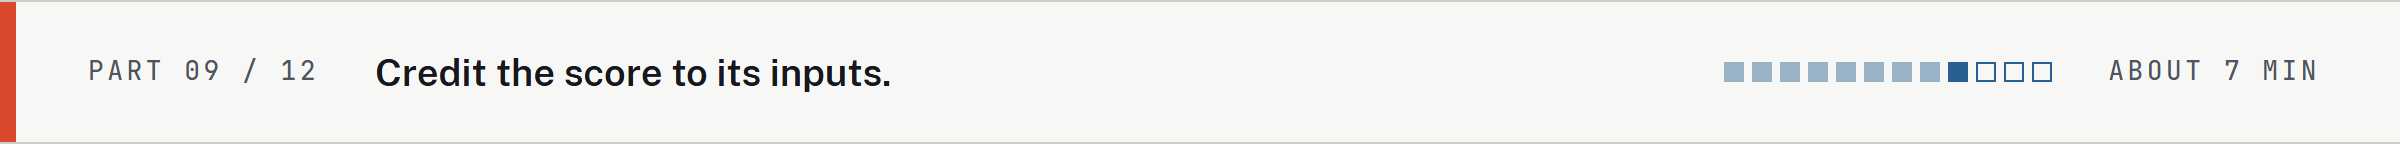

# What Drives the Score

A score that cannot be explained is hard to act on.
A **SHAP value** splits one firm-year's score among its inputs: how far each ratio pushed the score up or down from the average.

Ratios in one family carry much the same information, so the first reading adds SHAP values up by family.
A second method checks it: shuffle a whole family's columns among the firm-years and see how far the ROC-AUC falls.

Q. Which families of ratios drive the score?

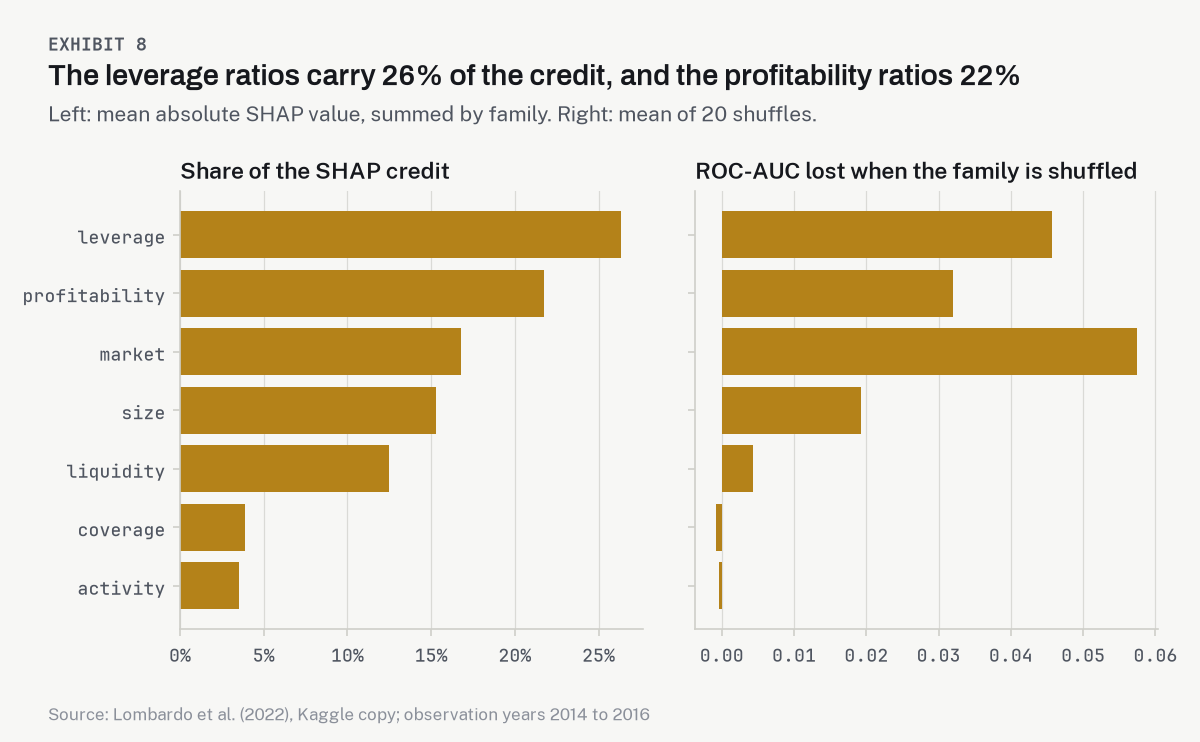

In [16]:
tree = fitted[CHOSEN]
inputs_holdout = tree.prepare(sealed)
explained = shap.TreeExplainer(tree.model)(inputs_holdout)
credit = pd.DataFrame(explained.values, columns=RATIOS)
FAMILY_OF = {name: family for family, members in FAMILIES.items() for name in members}

by_family = credit.abs().mean().groupby(FAMILY_OF).sum()
shap_share = (by_family / by_family.sum()).sort_values()

rng = np.random.default_rng(SEED)
REPEATS = 20
base_auc = roc_auc_score(sealed["target"], hold["pct"])
drops = {}
for family, members in FAMILIES.items():
    falls = []
    for _ in range(REPEATS):
        shuffled = inputs_holdout.copy()
        shuffled[members] = shuffled[members].to_numpy()[rng.permutation(len(shuffled))]
        pct = within_year_percentile(
            pd.Series(tree.model.predict_proba(shuffled)[:, 1]), sealed["year"]
        )
        falls.append(base_auc - roc_auc_score(sealed["target"], pct))
    drops[family] = np.mean(falls)
drops = pd.Series(drops)

fig, (left, right) = plt.subplots(1, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 3.6), sharey=True)
left.barh(shap_share.index, shap_share, color=COLORS["trees"])
right.barh(shap_share.index, drops[shap_share.index], color=COLORS["trees"])
left.set_title("Share of the SHAP credit")
right.set_title("ROC-AUC lost when the family is shuffled")
left.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
for ax in (left, right):
    ax.grid(axis="y", visible=False)

store.put("top_family", shap_share.index[-1])
store.put("top_family_share", shap_share.iloc[-1])
store.put("second_family", shap_share.index[-2])
store.put("second_family_share", shap_share.iloc[-2])
store.put("top_family_drop", drops[shap_share.index[-1]])
store.put("top_by_shuffle", drops.idxmax())
# The readings say: leverage leads by SHAP, the market family by shuffling, and coverage and
# activity are last by both.
assert shap_share.index[-1] == "leverage" and drops.idxmax() == "market"
assert (
    set(shap_share.index[:2])
    == set(drops.abs().sort_values().index[:2])
    == {"coverage", "activity"}
)

viz.exhibit(
    fig,
    f"The {shap_share.index[-1]} ratios carry {shap_share.iloc[-1]:.0%} of the credit, and the "
    f"{shap_share.index[-2]} ratios {shap_share.iloc[-2]:.0%}",
    f"Left: mean absolute SHAP value, summed by family. Right: mean of {REPEATS} shuffles.",
    f"{SOURCE}; observation years {HOLDOUT[0]} to {HOLDOUT[1]}",
)

**Reading.** Exhibit 8 gives two answers that agree on the leaders and not on their order.
By SHAP credit the leverage ratios lead with 26%, then profitability with 22%.

By shuffling, the market family costs the most.
SHAP shares credit among ratios that say similar things, and shuffling asks what is lost when a family goes missing, so the market's view looks like the information least repeated elsewhere.

Coverage and activity matter least by either method.

Q. Which single ratios matter most, and in which direction?

,rank correlation of the ratio with its SHAP value
mve_to_liabilities,-0.84
debt_to_ebitda,0.56
quick_ratio,-0.89
log_market_cap,-0.73
net_margin,-0.78
liabilities_to_assets,0.90
retained_earnings_to_assets,-0.74
ebitda_margin,-0.90


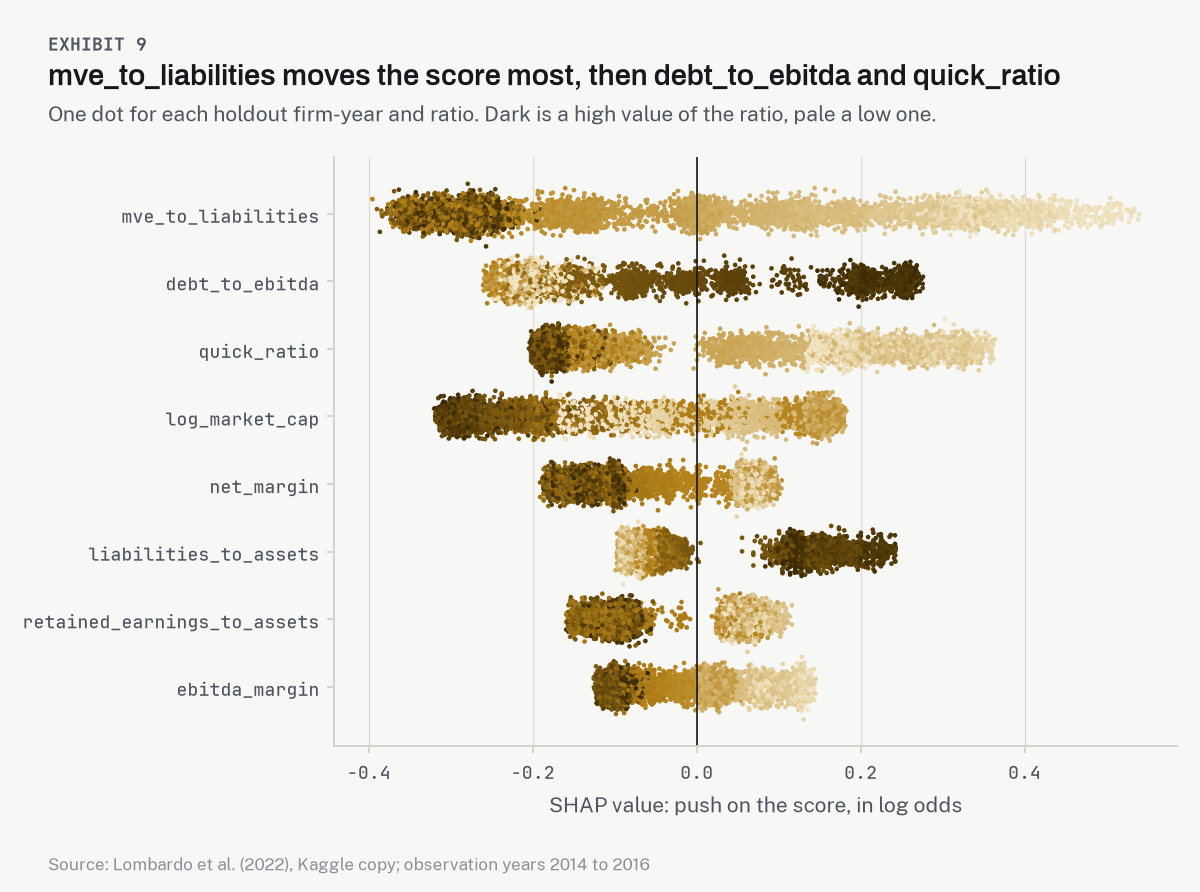

In [17]:
TOP = credit.abs().mean().sort_values(ascending=False).index[:8]
rank_of = inputs_holdout[RATIOS].rank(pct=True)
ramp = LinearSegmentedColormap.from_list("ramp", ["#F1E4C3", COLORS["trees"], "#3B2A05"])
jitter = np.random.default_rng(SEED).normal(0, 0.11, len(credit))

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 4.6))
for y_at, name in enumerate(TOP[::-1]):
    ax.scatter(credit[name], y_at + jitter, c=rank_of[name], cmap=ramp, s=5, linewidths=0,
               rasterized=True)  # fmt: skip
ax.axvline(0, color=viz.INK, linewidth=0.8)
ax.set_yticks(range(len(TOP)), TOP[::-1])
ax.set_xlabel("SHAP value: push on the score, in log odds")
ax.grid(axis="y", visible=False)

direction = pd.Series({name: credit[name].corr(rank_of[name], method="spearman") for name in TOP})
store.put("top_ratio", TOP[0])
store.put("second_ratio", TOP[1])
store.put("third_ratio", TOP[2])
store.put("top_ratio_share", credit[TOP[0]].abs().mean() / credit.abs().mean().sum())
# The reading says each leading ratio pushes the way a credit analyst expects. Checked here.
RAISES_RISK_WHEN_HIGH = {"debt_to_ebitda", "liabilities_to_assets"}
assert all((direction[name] > 0) == (name in RAISES_RISK_WHEN_HIGH) for name in TOP)
assert TOP[0] == "mve_to_liabilities"

viz.exhibit(
    fig,
    f"{TOP[0]} moves the score most, then {TOP[1]} and {TOP[2]}",
    "One dot for each holdout firm-year and ratio. Dark is a high value of the ratio, pale a low one.",
    f"{SOURCE}; observation years {HOLDOUT[0]} to {HOLDOUT[1]}",
)
direction.round(2).to_frame("rank correlation of the ratio with its SHAP value")

**Reading.** In Exhibit 9 a ratio whose dark dots sit on the right pushes the score up when it is high.
`mve_to_liabilities` leads, with 16% of all the credit: a small market value beside the liabilities pushes the score up, and a large one pushes it down.

Debt over EBITDA and liabilities over assets raise the score when they are high, and the other six lower it.
Each direction is the one a credit analyst would expect.

Q. How does the push change along each of the three leading ratios?

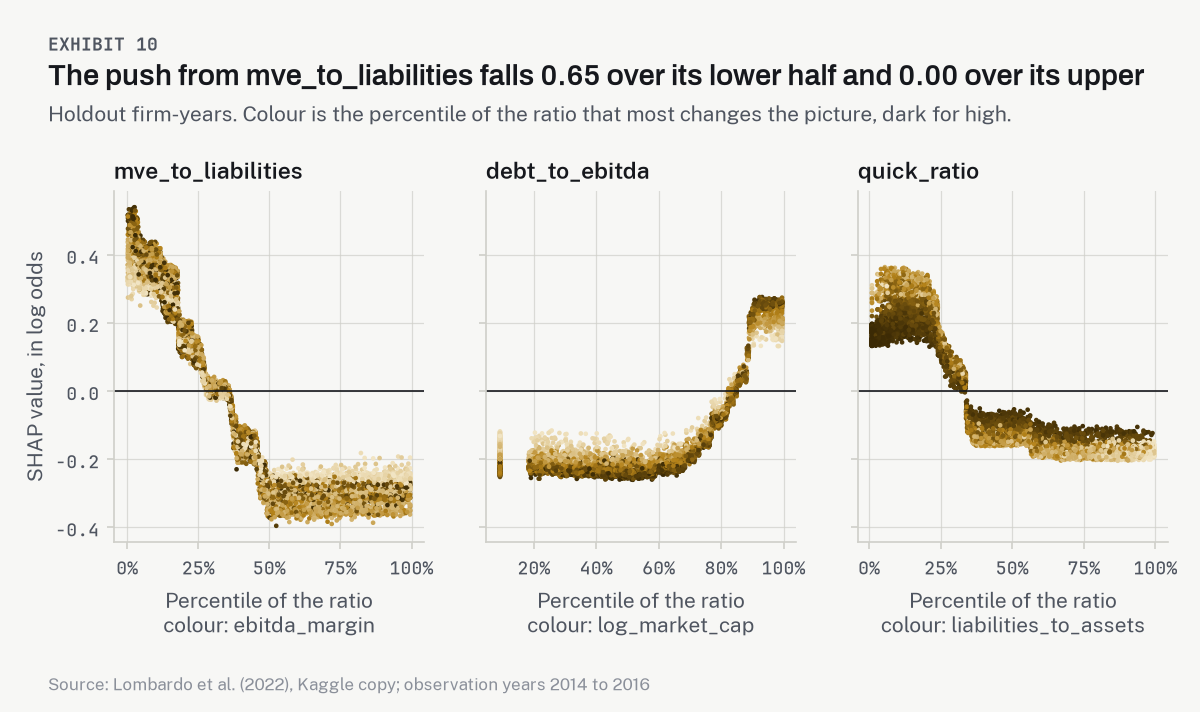

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(viz.EXHIBIT_WIDTH_IN, 3.4), sharey=True)
partners = {}
for ax, name in zip(axes, TOP[:3]):
    partner = RATIOS[shap.utils.potential_interactions(explained[:, name], explained)[0]]
    partners[name] = partner
    ax.scatter(rank_of[name], credit[name], c=rank_of[partner], cmap=ramp, s=5, linewidths=0,
               rasterized=True)  # fmt: skip
    ax.axhline(0, color=viz.INK, linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel(f"Percentile of the ratio\ncolour: {partner}")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel("SHAP value, in log odds")

middle = credit.loc[rank_of[TOP[0]].between(0.45, 0.55), TOP[0]].median()
lower_fall = credit.loc[rank_of[TOP[0]] < 0.1, TOP[0]].median() - middle
upper_fall = middle - credit.loc[rank_of[TOP[0]] > 0.9, TOP[0]].median()
# The reading says the push falls steeply through the lower half and is nearly flat above it.
assert upper_fall < 0.25 * lower_fall
viz.exhibit(
    fig,
    f"The push from {TOP[0]} falls {lower_fall:.2f} over its lower half and {upper_fall:.2f} over "
    "its upper",
    "Holdout firm-years. Colour is the percentile of the ratio that most changes the picture, "
    "dark for high.",
    f"{SOURCE}; observation years {HOLDOUT[0]} to {HOLDOUT[1]}",
)

**Reading.** Exhibit 10 shows shapes a straight line could not draw.
The push from `mve_to_liabilities` falls steeply through the lower half of its range and then goes flat: past the middle, more market value buys little more safety.

The other two are closer to steps, with debt over EBITDA adding risk only at its high end and the quick ratio only at its low end.
Thresholds of this kind are what the trees added to the logistic regression in Chapter 5.

**Next, three companies.**

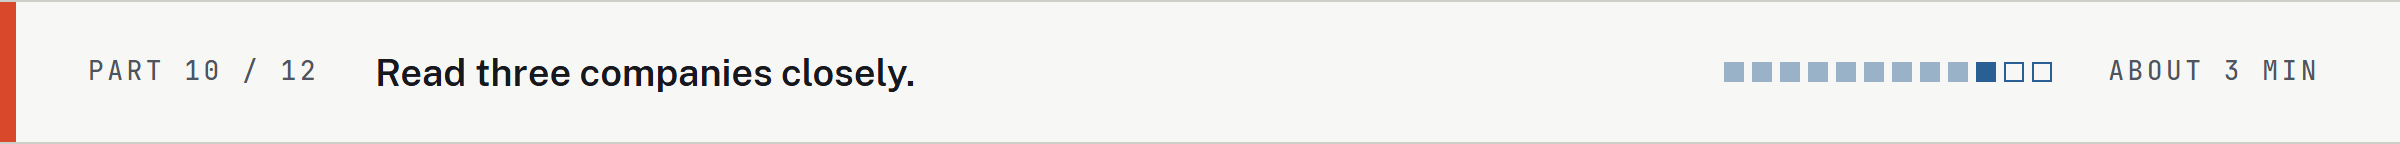

# Three Case Files

Averages hide companies, so three are read closely.
They are chosen by a rule, so that no one can pick the flattering ones.

Among the failures the model put in its top 5%, the one at the median score is the **caught** case.
Among the failures it did not, the one at the median score is the **missed** case, and among the flagged firm-years that did not fail, the one at the median score is the **false alarm**.

Q. Who are they, and what did the model see?

,company,year,percentile,grade,PD,last filing,status,main push
case,,,,,,,,
Caught,C_2335,2014,0.988,7,0.117,2015,failed,mve_to_liabilities
Missed,C_5837,2016,0.772,3,0.028,2018,failed,log_assets
False alarm,C_4564,2014,0.973,6,0.074,2015,alive,mve_to_liabilities


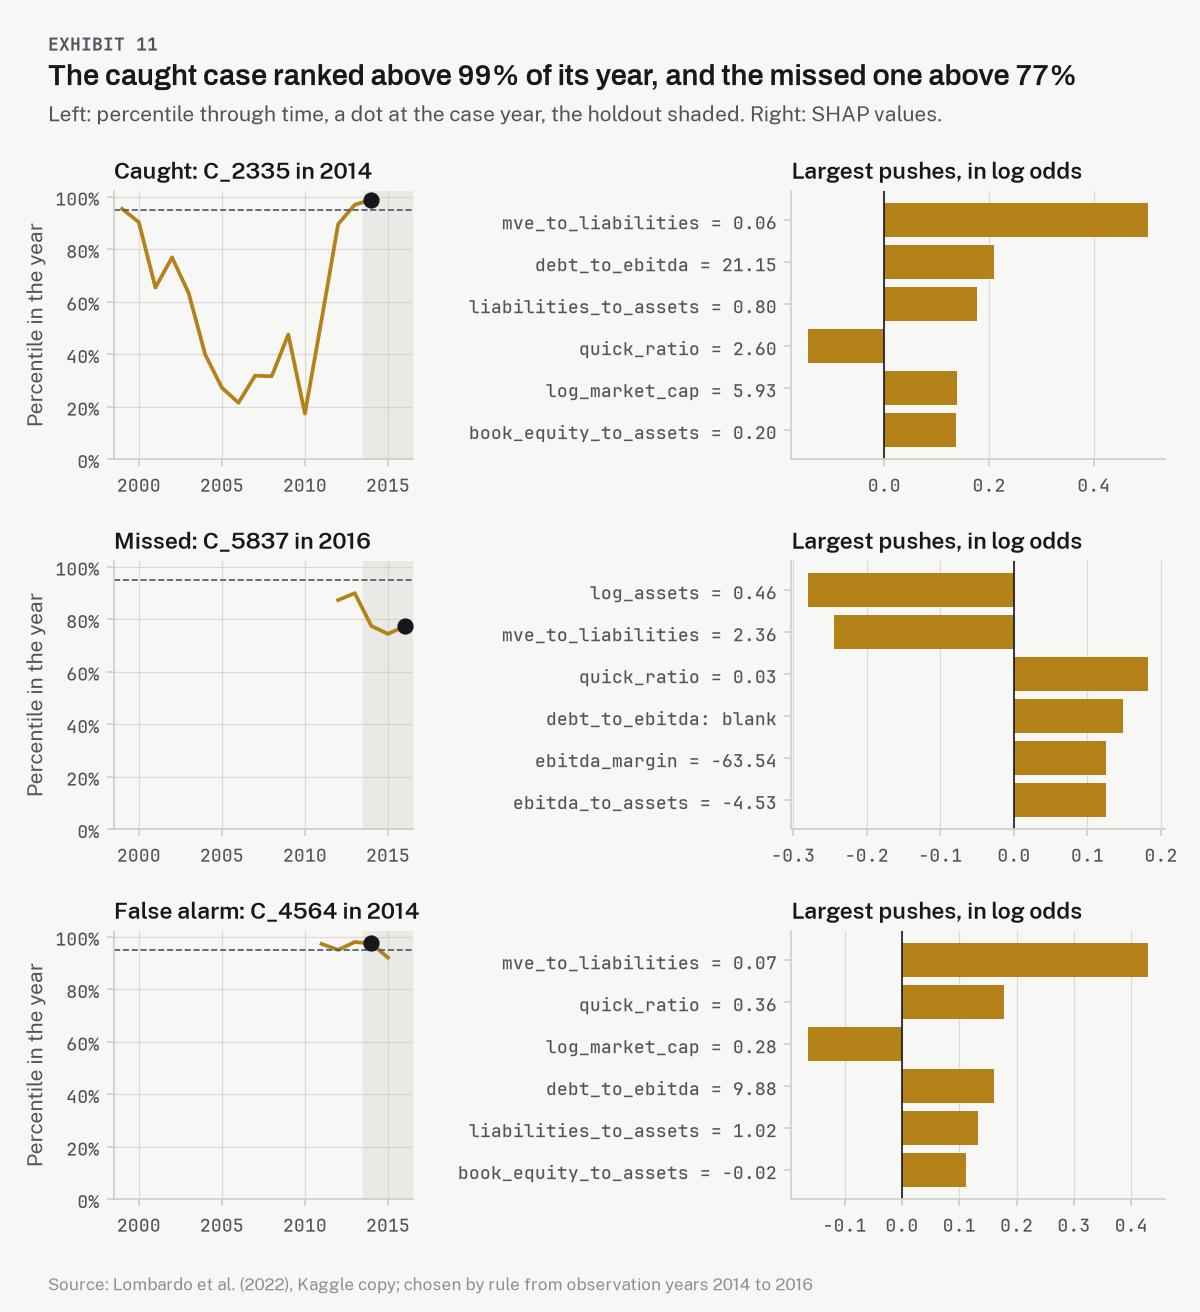

In [19]:
BUDGET = 0.05
flagged = (hold["pct"] > 1 - BUDGET).to_numpy()
failed_soon = (sealed["target"] == 1).to_numpy()


def median_case(keep: np.ndarray) -> int:
    """The row at the median score among the rows kept."""
    ordered = hold.loc[keep].sort_values(["pct", "company_name"])
    return int(ordered.index[len(ordered) // 2])


CASES = {
    "Caught": median_case(failed_soon & flagged),
    "Missed": median_case(failed_soon & ~flagged),
    "False alarm": median_case(~failed_soon & flagged),
}
# Every firm-year of the panel scored by the final model. The development years are years it trained on.
everything = features[[*KEYS]].assign(score=tree(features))
everything = everything.assign(pct=within_year_percentile(everything["score"], everything["year"]))

fig, axes = plt.subplots(len(CASES), 2, figsize=(viz.EXHIBIT_WIDTH_IN, 7.4), width_ratios=(1, 1.25))
files = []
for (path, bars), (label, row) in zip(axes, CASES.items()):
    company, year = sealed.loc[row, "company_name"], int(sealed.loc[row, "year"])
    history = everything.loc[everything["company_name"] == company].sort_values("year")
    path.plot(history["year"], history["pct"], color=COLORS["trees"], linewidth=1.8)
    path.scatter(year, hold.loc[row, "pct"], s=46, color=viz.INK, zorder=3)
    path.axhline(1 - BUDGET, color=viz.SLATE, linewidth=0.8, linestyle="--")
    path.axvspan(HOLDOUT[0] - 0.5, HOLDOUT[1] + 0.5, color=viz.RULE, alpha=0.35, linewidth=0)
    path.set_xlim(int(features["year"].min()) - 0.5, HOLDOUT[1] + 0.5)
    path.set_ylim(0, 1.02)
    path.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    path.set_title(f"{label}: {company} in {year}")
    path.set_ylabel("Percentile in the year")
    pushes = credit.loc[row].sort_values(key=np.abs, ascending=False).iloc[:6][::-1]
    values = inputs_holdout.loc[row, pushes.index]
    names = [
        f"{name} = {value:,.2f}" if pd.notna(value) else f"{name}: blank"
        for name, value in values.items()
    ]
    bars.barh(names, pushes, color=COLORS["trees"])
    bars.axvline(0, color=viz.INK, linewidth=0.8)
    bars.set_title("Largest pushes, in log odds")
    bars.grid(axis="y", visible=False)
    files.append({"case": label, "company": company, "year": year, "percentile": hold.loc[row, "pct"],
                  "grade": int(grade_of(hold.loc[[row], "pct"])[0]), "PD": pd_holdout[row],
                  "last filing": int(sealed.loc[row, "last_year"]), "status": sealed.loc[row, "status_label"],
                  "main push": pushes.index[-1]})  # fmt: skip
files = pd.DataFrame(files).set_index("case")

store.put("budget", BUDGET)
store.put("n_caught", int((failed_soon & flagged).sum()))
store.put("n_missed", int((failed_soon & ~flagged).sum()))
store.put("n_alarms", int((~failed_soon & flagged).sum()))
for label, row in files.iterrows():
    key = label.lower().replace(" ", "_")
    store.put(f"{key}_pct", row["percentile"])
    store.put(f"{key}_push", row["main push"])
    store.put(f"{key}_year", int(row["year"]))
    store.put(f"{key}_last", int(row["last filing"]))
store.put("alarm_status", files.loc["False alarm", "status"])
# The readings say: the caught case climbed for three years, the missed case is an unconfirmed
# failure, and the false alarm left the file a year later without being marked as failed.
caught_path = everything.loc[
    everything["company_name"] == files.loc["Caught", "company"]
].set_index("year")["pct"]
assert caught_path.loc[
    files.loc["Caught", "year"] - 3 : files.loc["Caught", "year"]
].is_monotonic_increasing
assert files.loc["Missed", "last filing"] == PANEL_END
assert files.loc["False alarm", "status"] == "alive"
assert files.loc["False alarm", "last filing"] == files.loc["False alarm", "year"] + 1

viz.exhibit(
    fig,
    f"The caught case ranked above {files.loc['Caught', 'percentile']:.0%} of its year, and the "
    f"missed one above {files.loc['Missed', 'percentile']:.0%}",
    "Left: percentile through time, a dot at the case year, the holdout shaded. Right: SHAP values.",
    f"{SOURCE}; chosen by rule from observation years {HOLDOUT[0]} to {HOLDOUT[1]}",
)
files.round(3)

**Reading.** Of the 500 firm-years on the desk's list, 57 failed within two years and 443 did not, and the list missed 103 failures.

The caught case ranked above 99% of its year in 2014 and filed for the last time in 2015.
In Exhibit 11 its rank climbs for three years before that, and its largest push is a market value that is a small fraction of its liabilities.

The missed case ranked above 77%, high and not on the list.
Its losses pushed the score up, and its small size and a market value above its liabilities pushed it down; it is also one of the unconfirmed failures.

The false alarm looks like the caught case on paper.
It filed for the last time in 2015, a year after the flag, and the file marks it "alive", which Chapter 2 warned is not the same as healthy.

**Next, how early the model sees a failure coming.**

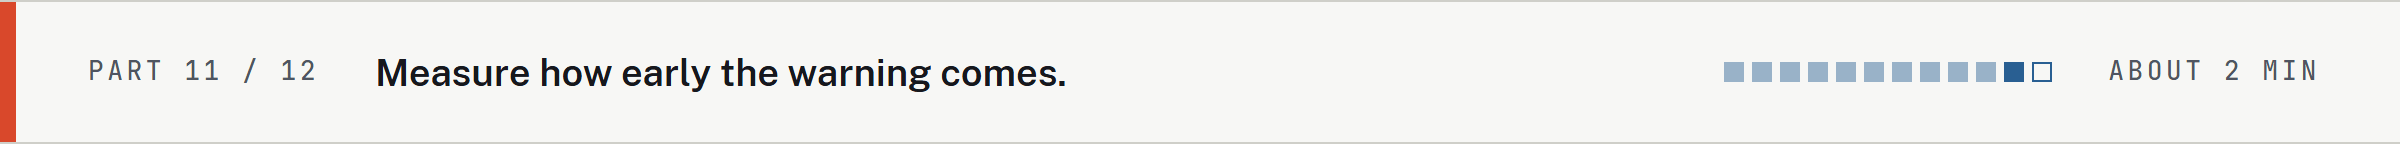

# How Early Does It See

A warning one year before the final filing helps less than one three years before.
The holdout holds firm-years of failed companies from one to four years ahead of their final filing.

Q. How high does the model rank a failing company as the final filing nears?

,rows,median,low,high,flagged,share flagged
years,,,,,,
1,80,0.906,0.785,0.979,29,0.362
2,80,0.844,0.638,0.975,28,0.350
3,50,0.776,0.606,0.921,8,0.160
4,31,0.685,0.486,0.818,0,0.000


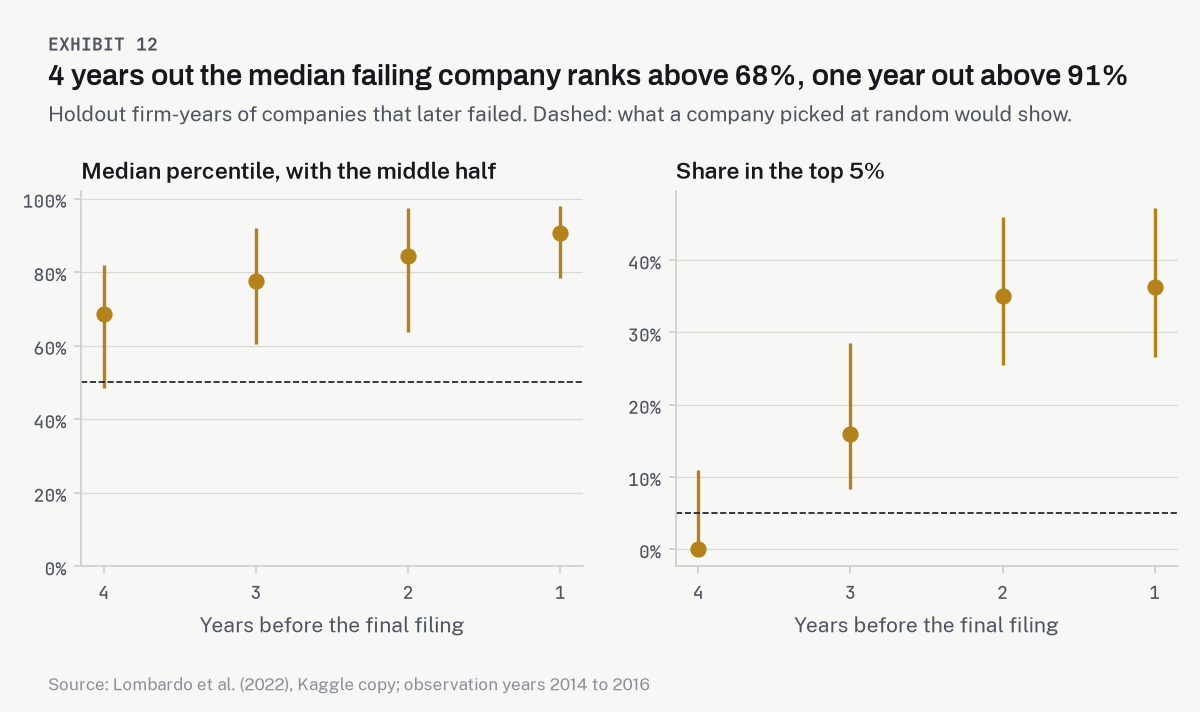

In [20]:
doomed = sealed["failed"].astype(bool).to_numpy() & (sealed["years_to_final"] >= 1).to_numpy()
ahead = (
    hold.loc[doomed]
    .assign(years=sealed.loc[doomed, "years_to_final"].astype(int), flag=flagged[doomed])
    .groupby("years")
    .agg(
        rows=("pct", "size"),
        median=("pct", "median"),
        low=("pct", lambda s: s.quantile(0.25)),
        high=("pct", lambda s: s.quantile(0.75)),
        flagged=("flag", "sum"),
    )
)
flag_bounds = np.array(
    [wilson_interval(int(k), int(n)) for k, n in zip(ahead["flagged"], ahead["rows"])]
)
ahead["share flagged"] = ahead["flagged"] / ahead["rows"]

fig, (rank, share) = plt.subplots(1, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 3.4))
rank.vlines(ahead.index, ahead["low"], ahead["high"], color=COLORS["trees"], linewidth=1.6)
rank.scatter(ahead.index, ahead["median"], s=46, color=COLORS["trees"], zorder=3)
rank.axhline(0.5, color=viz.INK, linewidth=0.8, linestyle="--")
rank.set_title("Median percentile, with the middle half")
rank.set_ylim(0, 1.02)
share.vlines(
    ahead.index, flag_bounds[:, 0], flag_bounds[:, 1], color=COLORS["trees"], linewidth=1.6
)
share.scatter(ahead.index, ahead["share flagged"], s=46, color=COLORS["trees"], zorder=3)
share.axhline(BUDGET, color=viz.INK, linewidth=0.8, linestyle="--")
share.set_title(f"Share in the top {BUDGET:.0%}")
for ax in (rank, share):
    ax.invert_xaxis()
    ax.set_xticks(ahead.index)
    ax.set_xlabel("Years before the final filing")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="x", visible=False)

for years in (ahead.index.min(), ahead.index.max()):
    store.put(f"median_{years}_out", ahead.loc[years, "median"])
    store.put(f"flagged_{years}_out", ahead.loc[years, "share flagged"])
store.put("farthest", int(ahead.index.max()))
# The readings say the rank rises as the final filing nears, and nothing four years out is flagged.
assert ahead["median"].is_monotonic_decreasing
assert ahead.loc[ahead.index.max(), "flagged"] == 0

viz.exhibit(
    fig,
    f"{ahead.index.max()} years out the median failing company ranks above "
    f"{ahead.loc[ahead.index.max(), 'median']:.0%}, one year out above {ahead.loc[1, 'median']:.0%}",
    "Holdout firm-years of companies that later failed. Dashed: what a company picked at random "
    "would show.",
    f"{SOURCE}; observation years {HOLDOUT[0]} to {HOLDOUT[1]}",
)
ahead.round(3)

**Reading.** In Exhibit 12 the warning builds over years.
4 years before the final filing the median failing company already ranks above 68% of its year, where a company picked at random would rank above half.

One year out it ranks above 91%.
The list is slower than the rank: none of the firm-years 4 years out is in the top twentieth, and one year out 36% are.

So the model sees trouble early, as a drift up the ranking, and names it late.

**Next, what all of this rests on.**

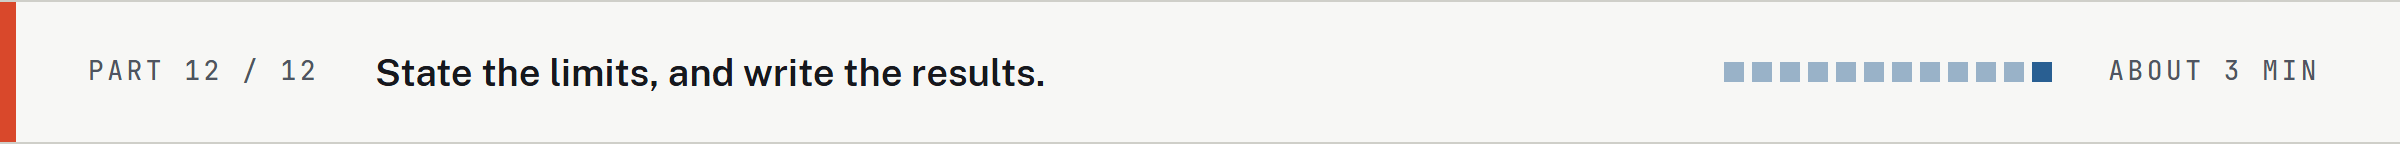

# Limits

A result is only as good as the account of what it rests on.
The cell below measures four of the limits, and writes the results the front page quotes.

Q. What should a reader hold against these numbers?

In [21]:
events = store.load_frame("event_table")  # Chapter 2's table of how each company leaves the file
quiet = events.loc[events["event"] != "failed", "event"]
bounds_low, bounds_high = (fit_prepare(dev, RATIOS, impute=False)[k] for k in (1, 2))
at_ceiling = (sealed[RATIOS] > bounds_high).mean()

store.put("still_reporting", (quiet == "reporting").mean())
store.put("ceiling_ratio", at_ceiling.idxmax())
store.put("ceiling_share", at_ceiling.max())
store.put("model_age_low", HOLDOUT[0] - DEV_END)
store.put("model_age_high", HOLDOUT[1] - DEV_END)

metrics = {
    "scoreboard": board.reset_index().to_dict("records"),
    "paired": steps.reset_index().to_dict("records"),
    "ladder": both.reset_index(names="model").to_dict("records"),
    "calibration": grades_holdout.assign(pd_fixed=GRADE_PD).reset_index().to_dict("records"),
    "robustness": robust.reset_index().to_dict("records"),
}
claims = {
    "holdout_rows": f"{len(sealed):,}",
    "holdout_failures": f"{int(sealed['target'].sum())}",
    "chosen_model": CHOSEN,
    "holdout_auc": f"{top['roc_auc']:.3f}",
    "holdout_auc_interval": f"{top['roc_auc_lo']:.3f} to {top['roc_auc_hi']:.3f}",
    "walk_forward_auc": f"{walked_board['roc_auc']:.3f}",
    "classic_auc": f"{board.loc[CLASSIC, 'roc_auc']:.3f}",
    "primary_step": f"{primary['roc_auc_diff']:+.3f}",
    "primary_step_interval": f"{primary['roc_auc_diff_lo']:+.3f} to {primary['roc_auc_diff_hi']:+.3f}",
    "capture_5": f"{top['capture_5']:.1%}",
    "capture_5_interval": f"{top['capture_5_lo']:.1%} to {top['capture_5_hi']:.1%}",
    "lift_5": f"{top['lift_5']:.1f}",
    "unseen_auc": f"{robust.loc['Companies never seen', 'roc_auc']:.3f}",
}
store.write_results(metrics, claims)

pd.Series(claims).to_frame("what the front page quotes")

,what the front page quotes
holdout_rows,"9,954"
holdout_failures,160
chosen_model,"All ratios, trees"
holdout_auc,0.815
holdout_auc_interval,0.779 to 0.850
walk_forward_auc,0.776
classic_auc,0.716
primary_step,+0.099
primary_step_interval,+0.063 to +0.136
capture_5,35.6%


**Reading.** The results are written, and these are the limits to read them with.

The label:

- It is derived, not given: the file marks a company as failed, and the year of failure is taken to follow its last filing, on the paper's own rule.
- Bankruptcy is not default: a missed coupon or a distressed exchange is not in the file.
- A company that stops filing without failing is counted as a survivor, and only 32% of the companies never marked as failed are still filing in the last year.
- 35 of the holdout's 160 failures cannot be confirmed by a later row.

The sample:

- These are small listed companies, not a universe of bond issuers.
- Early failures are thin: the first years of the file hold few, and the dot-com bust is never a validation year.
- 77% of holdout firm-years belong to companies the model trained on.
- Market value is among the inputs, so this is a market and accounting model, not an accounting one.
- Clipping bounds come from the development years, and 2.8% of the holdout values of `log_assets` sit above the upper bound.

The evidence:

- The holdout years have been scored more than once in the making of this study, so the walk-forward is the primary evidence and the holdout a check on it.
- The holdout holds no recession, and the evidence under stress comes from crisis folds that also took part in selection.
- Those crisis folds have the smallest training sets, so stress and sample size cannot be told apart.
- The panel holds one crisis.
- With 160 failures the holdout supports a coarse ordering of models, not gains from rung to rung.
- The model is 3 to 5 years old when the holdout scores it.
- The PD is an average over the cycle and will be wrong in most single years.

**That is the verdict, and the casebook ends here.**

# Findings

1. On the holdout the chosen model has a ROC-AUC of 0.815, with an interval from 0.779 to 0.850, above its walk-forward score of 0.776 (Exhibit 4).
2. The primary comparison is settled: the chosen model is 0.099 ahead of the published Altman Z, with an interval above zero (Exhibit 4).
3. The top twentieth of each year holds 35.6% of the failures, where the published score finds 5.6% (Exhibit 5).
4. The broad order of the ladder holds and the fine order does not: 2 of 6 steps are clear of zero, and history is a step of 0.013 where the walk-forward had a step down (Exhibit 4).
5. A PD built from the percentile is an average over the cycle: by year it stays between 1.8% and 2.0% while the share that failed runs from 1.3% to 2.8% (Exhibit 2).
6. The seven grades keep their order on the holdout, and the PD fixed beforehand is inside the interval for 4 of them (Exhibit 6).
7. On companies it never saw the model scores 0.722, with an interval from 0.601 to 0.832, against 0.841 on companies from the development years (Exhibit 7).
8. Leverage, profitability, and the market's view drive the score, and market value over liabilities is the leading ratio (Exhibit 8, Exhibit 9).
9. A failing company ranks above 68% of its year 4 years before its final filing and above 91% one year before (Exhibit 12).

# Your Turn

Three extensions, each with a hint folded under it.

**1. A fresher model.** The model is three to five years old when it is scored. How much does it gain if it is refitted each year, as a desk would refit it?

<details>
<summary>Hint</summary>

For each holdout year, fit `fit_trees` on the rows of `features` up to three years earlier and score that year alone.
Join the three years and compare with `verdict[CHOSEN]` through `paired_table`.

</details>

**2. A level for the cycle.** The PD is flat across years. Can last year's failure rate move it in the right direction?

<details>
<summary>Hint</summary>

The failures known at the start of a year are those with a final filing two or more years back.
Scale `pd_holdout` by that known rate over `base_rate`, and compare the Brier score with `brier_holdout`.

</details>

**3. Another case.** The three case files sit at the median of their groups. What does the worst miss look like?

<details>
<summary>Hint</summary>

Sort `hold.loc[failed_soon & ~flagged]` by `pct` and take the first row.
Draw its path with `everything` and its pushes with `credit`, as the case files do.

</details>

[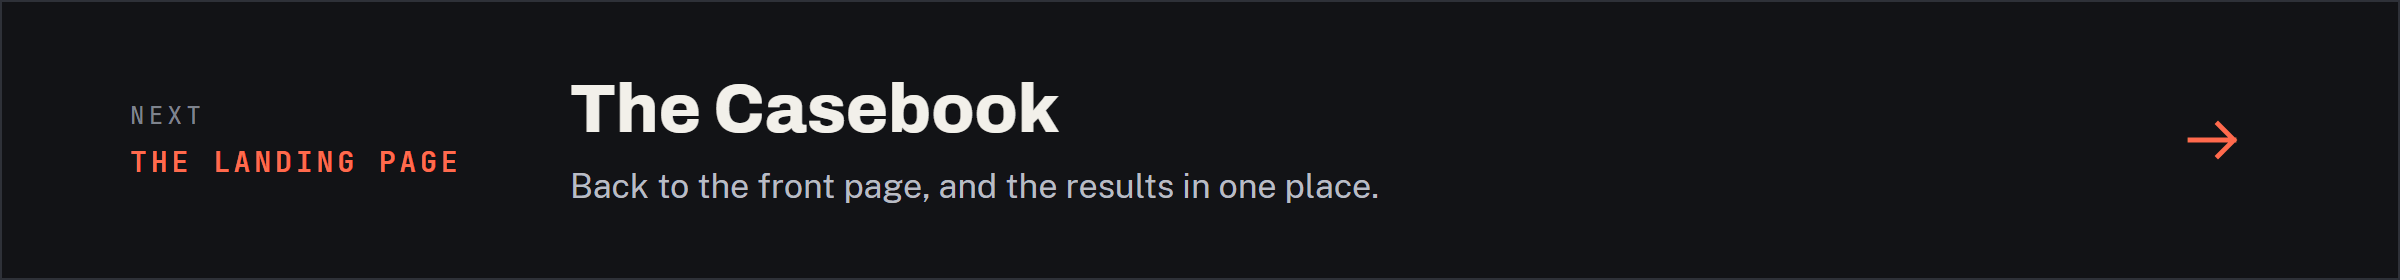](../README.md)